# Test 8: IRGA75 CO2 flux with random seed 2 of the gap-filling models

**notebook version**: `1` (6 Nov 2026). Test variant of `05_FPPC_IRGA75_NEE_OPCO_2004-2017`, as it stood on 6 Nov 2026.

## ℹ️ About this notebook

**Test variant of notebook `05_FPPC_IRGA75_NEE_OPCO_2004-2017`.** The XGBoost models of the gap-filling use `random_state=2` instead of 42, which changes the random test records, the cross-validation of the number of trees and the models. Together with the other seed test it shows the spread of the annual sums that comes from the models alone (plan item 8). Everything else is as in `05_FPPC_IRGA75_NEE_OPCO_2004-2017`. Its output file carries the name of this notebook, so it never overwrites the result of `05_FPPC_IRGA75_NEE_OPCO_2004-2017`. Overnight tests of 6 Nov 2026; the comparison of all of them is in `TESTS_T4-T12_COMPARISON_2026-11-06`.

Processes a CO2 flux with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): storage term (L3.1),
outliers (L3.2), USTAR filter (L3.3), gap-filling (L4.1), partitioning (L4.2) and uncertainty.
The site, flux, period and all settings are in *Settings*; *Data sources* links the site
documentation, which holds the decisions and periods specific to the site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet` in
the external data folder holds the Level-1 fluxes of the open-path IRGA75 (LI-7500), the meteo
data of the site, and the CO2 flux corrected with opco, `FC_L1.1_OPCO` (notebook `01`). After
loading, the corrected flux replaces `FC`, so the chain finds the quality flags, storage term and
random uncertainty of `FC` and names its results as for the IRGA72. The opco correction does not
change those: it shifts the flux of each half-hour by its bias.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.2.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2004  # the year with the most gap-filled meteo, a hard case for the partitioning
# Years to process: the full calendar years with IRGA75 fluxes. The input also holds 2018, without
# any IRGA75 flux, and 2019 with only the stand-in run of 17 January to 20 March; neither is
# gap-filled here.
YEARS = [TEST_YEAR] if TEST_RUN else list(range(2004, 2018))
RUN_PARTITIONING = True  # Level 4.2
# First measured SW_IN (TIMESTAMP_MIDDLE): the CNR1 radiometer from 14 September 2005 (site
# documentation, Instrumentation). The daytime partitioning fits only on measured SW_IN; before
# this record its results are extrapolated, not fitted, and are set to missing (Step 8).
DT_VALID_FROM = '2005-09-14 11:15'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "T8_05_FPPC_IRGA75_NEE_OPCO_SEED2_2004-2017"  # same name as this notebook
if TEST_RUN:
    OUTNAME += f"_TEST_{TEST_YEAR}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'FC'  # CO2 flux of the open-path LI-7500, replaced by CORRECTED_FLUXCOL after loading
CORRECTED_FLUXCOL = 'FC_L1.1_OPCO'  # the flux corrected with opco in notebook 01
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
LEVEL2_SETTINGS = {
    # AGC of the LI-7500 (%), in steps of 6.25: 50 is a very good signal, higher values mean dirt or
    # water on the windows. Records from 40 to 65 are kept: from an AGC of 68.75 the flux is biased
    # against the LI-7200 (2016-2017); 56.25 and 62.5 are noisier but kept.
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_AGC_IRGA75_MEAN',
                        'method': 'discard outside',
                        'threshold': (40, 65)},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.1 ---------------------------------------------------------------------------------
# The CO2 concentration the storage term SC_SINGLE is calculated from (mmol m-3). Next to a gap in
# it, the storage term is discarded where the analyser read off, and filled.
CO2_CONC = 'CO2_MOLAR_DENSITY'
# Readings of CO2_CONC used for the storage term. A wet or blocked optical path makes the LI-7500
# read the concentration tens of ppm too high, and after the gap that ends such an episode the
# reading returns to the real concentration over a few records. The return entered the storage
# term as a one-sided flux: it summed to -25 to -196 gC m-2 per year (2004-2017), that of the
# LI-7200 to about zero. In the 2016-2017 overlap the LI-7500 reads 33 to 106 ppm high at an AGC
# above 55 or after rain, and within a few ppm of the LI-7200 otherwise. A reading is used only at
# an AGC up to STORAGE_AGC_MAX, without rain in the previous STORAGE_RAIN_HOURS hours, below
# STORAGE_RH_MAX, and not among the first STORAGE_SKIP_AFTER_GAPS records after a gap. The storage
# values of the other readings are discarded and filled (Step 3).
METEOFILE = rf"{DATADIR}\10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"  # for PREC
PREC = 'PREC_TOT_T1_47_1'  # mm per half-hour
STORAGE_RH = 'RH_T1_47_1_HOMOGENIZED'  # %
STORAGE_AGC_MAX = 55
STORAGE_RAIN_HOURS = 3
STORAGE_RH_MAX = 99.5
STORAGE_SKIP_AFTER_GAPS = 3

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (date ranges, whole days, both ends included). The reasons are in the
# site documentation (Level 3.2).
REMOVE_DATES = [
    ['2004-12-01', '2004-12-15'],  # fog and rime: nighttime NEE -10 to -20, nighttime H positive
    ['2013-11-16', '2013-11-23'],  # fog and rime, as in December 2004
    ['2014-11-09', '2014-11-12'],  # fog and rime, as in December 2004
    ['2014-11-24', '2014-12-07'],  # fog and rime, as in December 2004
]
# Absolute limits (umol m-2 s-1), as for the IRGA72.
ABSLIM = (-50, 50)

# --- Level 3.3 ---------------------------------------------------------------------------------
# Constant USTAR thresholds (m s-1) of FP2026.2, the 16th, 50th and 84th percentiles of the
# bootstrap draws of the ONEFlux moving point method on the LI-7500 record 2004-2017, from
# 30_FLUX_POST-PROCESSING_CHAIN/USTAR_THRESHOLD_DETECTION_2004-2026.09, section 2 (3 Nov 2026;
# detected again on 4 Nov 2026, after the AGC window was narrowed to 40-65).
# Each analyser uses the set detected on its own record. The LI-7200 uses
# [0.4155, 0.5264, 0.6472] (2016-2025).
USTAR_THRESHOLDS = [0.3182, 0.4350, 0.5459]
USTAR_SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']

# --- Level 4.1 and 4.2: meteo drivers ----------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # built below from TA_F and TA_FLAG
SW_IN_MEAS = 'SW_IN_T1_47_1_MEASURED'        # built below from SW_IN_F and SW_IN_FLAG
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'µmol m-2 s-1'
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
# Level 3.2, test 5: nighttime values below -NIGHT_Z times their uncertainty NIGHT_UNC are removed.
# NIGHT_UNC is the larger of RANDUNC_COL and the median PAS20 uncertainty of the nighttime records
# of the same calendar month, over all years, combined in quadrature with OPCO_SIGMA.
NIGHT_Z = 4
# Uncertainty of the opco correction (umol m-2 s-1); opco gives none per half-hour. Source: notebook
# 01, table "what each version leaves against IRGA72 in the overlap": out of fold, the corrected
# IRGA75 differs from the IRGA72 at night by 0.85 on average (absolute), about 1.1 as a standard
# deviation, which includes the noise of both analysers. Calm nights below 0 degC remain about 1
# below the IRGA72 after the correction (site documentation, Known issues).
OPCO_SIGMA = 1.0
# Level 3.2, test 6: all records of a night are removed whose median lies below -NIGHTS_Z standard
# errors of that median: nights of apparent uptake, mostly in fog or rime on the open-path windows.
# The standard error combines the random error of the median and OPCO_SIGMA, which is shared by
# the records of a night.
NIGHTS_Z = 3
# Lag-1 autocorrelation of the nighttime values about their night median, 0.16 in 2004-2017 (0.21
# for the IRGA72); n records count as n (1 - r) / (1 + r) independent ones. Checked in Step 4.
NIGHTS_AUTOCORR = 0.2
NIGHTS_MIN_RECORDS = 6  # fewest nighttime values a night needs to be tested

# 30-min CO2 flux in umol m-2 s-1 -> gC m-2 per half-hour, for sums and cumulatives.
UMOL_TO_GC = 12.011 * 1e-6 * 1800

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=2,  # test 8
                    n_jobs=-1, shap_max_rows=5000)

# Wet nights (Level 4.1): XGBoost fills the night gaps of the LI-7500 in rain and fog too low, at about
# half of what the LI-7200 measured in the same half-hours of 2016-2017. A second fill takes XGBoost for
# all gaps and a Lloyd-Taylor model on the dry measured nights for the wet night gaps (diive
# run_level41_xgb_wetnight, columns _gfXGWN, flag 3), next to the plain XGBoost fill. Wet: rain in the
# previous WETNIGHT_RAIN_HOURS hours, a wet window (AGC at least WETNIGHT_AGC_MIN) or an overcast sky
# (cloudiness index at least WETNIGHT_CI_MIN). Dry, for the fit: no rain and no wet window. No RH
# threshold: the RH sensor change of January 2016 makes such thresholds select different nights.
RUN_WETNIGHT = True
WETNIGHT_RAIN_HOURS = 3
WETNIGHT_AGC_MIN = 56.25
WETNIGHT_CI_MIN = 0.8
LW_IN = 'LW_IN_T1_47_1'  # W m-2, from METEOFILE
# Cloudiness index (LW_IN / sigma TA^4 - q05) / (q95 - q05): 0 clear, 1 overcast. q05 and q95 are the night
# percentiles of the longwave ratio of the two LW_IN sensors, before and after their change on LW_CHANGE
# (research report coldnight_2026-11-03, C_conditions/c_common.py, in the external data folder).
LW_CHANGE = '2016-06-07'
LWR_Q05 = (0.640, 0.712)  # before, after LW_CHANGE
LWR_Q95 = (1.004, 0.996)
# The fill of the product (partitioning, the merged record): XGBoost with Lloyd-Taylor for the wet nights;
# plain XGBoost and MDS are kept for comparison. The stage merge copies its _gfXGWN columns into the
# product's _gfXG columns for the LI-7500 years.
PRODUCT_FILL = 'xgbwn' if RUN_WETNIGHT else 'xgb'

# --- Uncertainty -------------------------------------------------------------------------------
# Pastorello et al. (2020): random uncertainty of the reference scenario, USTAR uncertainty from
# the two outer scenarios.
UNC_REF = 'CUT_50'
UNC_LOWER, UNC_UPPER = 'CUT_16', 'CUT_84'

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.preprocessing.outlier_detection.negativenights import night_of
from diive.flux.postprocessingchain import (
    add_driver,
    init_flux_data,
    make_level32_detector,
    nighttime_uncertainty,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    run_level41_xgb_wetnight,
    run_level42_partitioning,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_gapfilling_input_timeseries,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-11-06 21:46:28
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
df = df.loc[df.index.year.isin(YEARS)].copy()
assert sorted(set(df.index.year)) == sorted(YEARS), f"the input lacks some of the years {YEARS}"
assert (df.index[0], df.index[-1]) == (pd.Timestamp(f'{min(YEARS)}-01-01 00:15'),
                                       pd.Timestamp(f'{max(YEARS)}-12-31 23:45')), \
    f"the selected years run from {df.index[0]} to {df.index[-1]}, not over whole calendar years"

for _c in [FLUXCOL, CORRECTED_FLUXCOL, CO2_CONC, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"

# The chain processes the corrected flux under the name FC (see Data sources).
print(f"{FLUXCOL} (uncorrected): {df[FLUXCOL].notna().sum():,} records; "
      f"{CORRECTED_FLUXCOL}: {df[CORRECTED_FLUXCOL].notna().sum():,} records")
df[FLUXCOL] = df[CORRECTED_FLUXCOL]
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL} (now the corrected flux): {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet (0.355 seconds).

FC (uncorrected): 216,243 records; FC_L1.1_OPCO: 197,858 records
245,472 records x 366 columns, 2004-01-01 00:15:00 -> 2017-12-31 23:45:00
FC (now the corrected flux): 197,858 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'FC'
  levels run  = []
  fpc_df      = 245472 rows x 5 cols
  columns     = [FC, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`, e.g. steady state and developed turbulence (SSITC), the spectral
correction factor, the signal strength of the analyser and spikes and dropouts in the raw data
(Vickers and Mahrt 1997). The table shows how many records each test removes.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_FC_SSITC_TEST, values taken from output variable
FC_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_FC_SCF_TEST, newly 
calculated from output variable FC_SCF, with flag 0 (good values) where FC_SCF < 2, flag 1 (ok 
values) where FC_SCF >= 2 and < 4, flag 2 (bad values) where FC_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_FC_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_AGC_IRGA75_MEAN, with flag 0 (good values) where 40 <= 
CUSTOM_AGC_IRGA75_MEAN <= 65, flag 2 (bad values) where it is below 40 or above 65 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_SPIKE_HF_TEST, values taken from 
output variable CO2_VM97_TEST from position 1, based on CO2, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_DROPOUT_HF_TEST, values taken 
from output variable CO2_VM97_TEST from position 3, based on CO2, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 146,473 valid records


### 📊 Plot: Level-2 quality flag over time

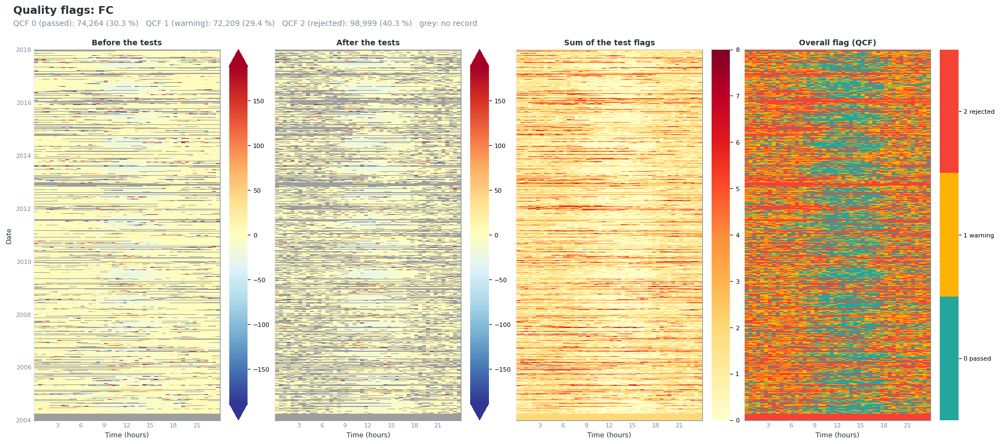

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: FC
Measured records: 197,858 of 245,472
Missing records: 47,614 (19.40 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                 all      197,858    77,044   79,063   41,751   21.10        0
                            day      100,481    51,863   33,888   14,730   14.66        0
                            night     97,377    25,181   45,175   27,021   27.75        0
                                                                                         
L2_FC_SCF                   all      197,858   197,858        0        0    0.00        0
                            day      100,481   100,481        0        0    0.00        0
                            night     97,377    97,377        0        0    0.00        0
                                                                                         
L2_FC_SIGNAL_STRENGTH       all      197,858   185,670        0   12,188    6.16        0
                            day      100,481    94,860        0    5,621    5.59        0
                            night     97,377    90,810        0    6,567    6.74        0
                                                                                         
L2_FC_CO2_VM97_SPIKE_HF     all      197,858   195,048        0    2,810    1.42        0
                            day      100,481    99,266        0    1,215    1.21        0
                            night     97,377    95,782        0    1,595    1.64        0
                                                                                         
L2_FC_CO2_VM97_DROPOUT_HF   all      197,858   197,858        0        0    0.00        0
                            day      100,481   100,481        0        0    0.00        0
                            night     97,377    97,377        0        0    0.00        0

## Step 3: storage term (Level 3.1)

Adds the storage term to the flux (`FC + SC_SINGLE`), after two screening steps:

- **Next to gaps** in `CO2_CONC`: after a signal loss an analyser can restart far from the real
  concentration, and its return would count as a one-sided storage flux. The storage values are
  discarded until the concentration is normal again for its time of day.
- **Invalid readings** of the LI-7500: at an AGC above `STORAGE_AGC_MAX`, after rain, in saturated
  air (`STORAGE_RH_MAX`) and in the first `STORAGE_SKIP_AFTER_GAPS` records after a gap the
  analyser can read tens of ppm too high (Settings). The storage values that use such a reading are
  discarded. Where they lie between two valid readings, they are replaced by their mean, which keeps
  the concentration change between the valid readings.
- **Spikes**: each isolated spike, with one record on either side, is replaced by the block mean,
  which keeps the sum.

The other removed values are filled with a rolling median, so every measured flux keeps a storage
term.
Details: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term).

In [8]:
_prec = pd.read_parquet(METEOFILE, columns=[PREC])[PREC].reindex(df.index)
_rain = _prec.rolling(2 * STORAGE_RAIN_HOURS, min_periods=1).sum() > 0
_agc = df[LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]
CO2_CONC_VALID = ((_agc <= STORAGE_AGC_MAX) & ~_rain & (df[STORAGE_RH] < STORAGE_RH_MAX)).rename('CO2_CONC_VALID')
print(f"{CO2_CONC}: {df[CO2_CONC].notna().sum():,} readings, "
      f"{(df[CO2_CONC].notna() & ~CO2_CONC_VALID).sum():,} of them invalid for the storage term")

data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False,
                   screen_storage_term=True, concentration_col=CO2_CONC,
                   concentration_valid=CO2_CONC_VALID,
                   restart_screening={'skip_after_gaps': STORAGE_SKIP_AFTER_GAPS})
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

CO2_MOLAR_DENSITY: 216,243 readings, 61,917 of them invalid for the storage term


────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux NEE_L3.1 from flux FC + storage term SC_SINGLE

> Storage term SC_SINGLE: 73,584 reading(s) of CO2_MOLAR_DENSITY set aside as invalid

> Storage term SC_SINGLE: 186 analyser restart(s) after a gap in CO2_MOLAR_DENSITY; 73,707 storage
value(s) discarded where the concentration was off or invalid next to a gap

> Storage term SC_SINGLE: 3,887 spike(s) found (2.81 % of the measured storage values)

> Storage term SC_SINGLE: 25,739 value(s) over invalid readings between two valid ones replaced by
the mean of their stretch

> Storage term SC_SINGLE: 8,754 value(s) replaced by the mean of their block (spikes and one 
record on either side)

After L3.1: 146,473 valid records (col: NEE_L3.1_QCF)


### 📊 Plot: storage term screening

The daily cycle should stay positive at night with a dip in the morning, the spikes should have
both signs, and the cumulative sum should stay near zero. A drift that remains usually lies in
periods when the analyser was failing; check that the quality flags remove their fluxes.

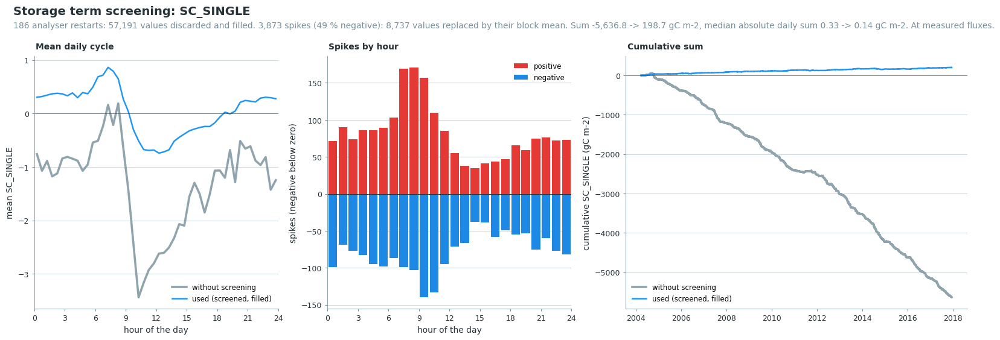

In [9]:
data.levels.level31.plot_screening(gain=UMOL_TO_GC, units='gC m-2');

## Step 4: outlier removal (Level 3.2)

Seven tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reasons are in the site documentation.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.
5. Hampel filter per time of day over 31 days: extreme values in windows too sparse or too
   noisy for the 13-day filter.
6. Nighttime values clearly below zero.
7. Whole nights whose median lies clearly below zero.

How the tests work: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists
further tests.

In [10]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

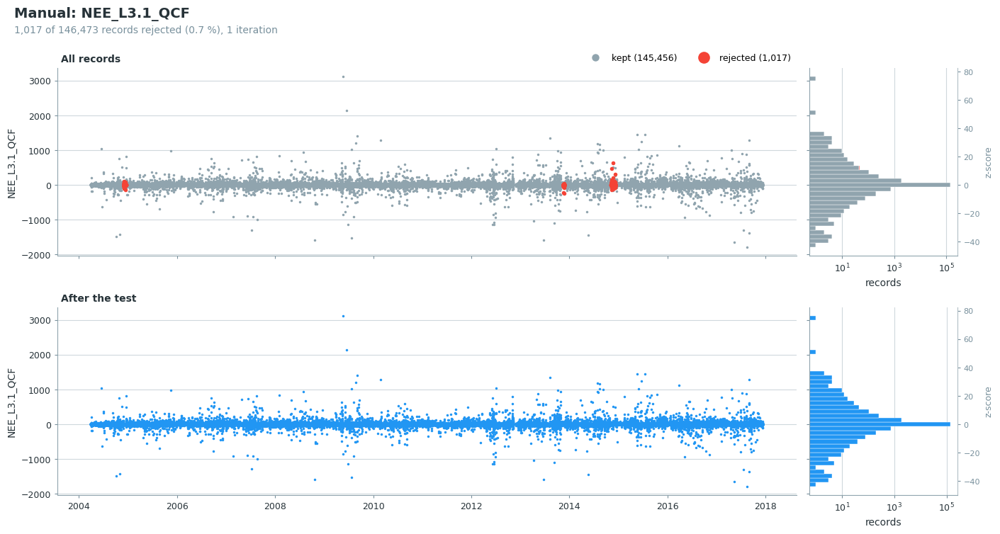

In [11]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [12]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

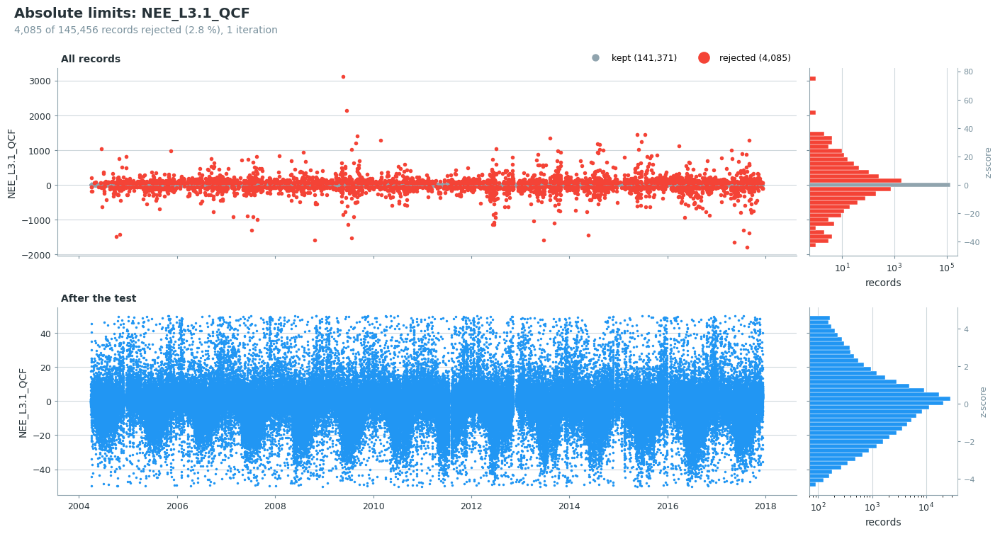

In [13]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [14]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  2675 (  1.89%) | Day:   902 | Night:  1773

[Dt/Nt] ITER #02 | Outliers:   377 (  0.27%) | Day:    98 | Night:   279

[Dt/Nt] ITER #03 | Outliers:    58 (  0.04%) | Day:    13 | Night:    45

[Dt/Nt] ITER #04 | Outliers:     3 (  0.00%) | Day:     0 | Night:     3

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 12 record(s) could not be judged because the local MAD was exactly zero (more than half 
the window identical) and were left unflagged. Typical causes: coarser data upsampled onto a finer 
grid, quantized readings, or a stuck sensor. Consider a longer window_length, 
use_differencing=False, or screening the affected period separately.

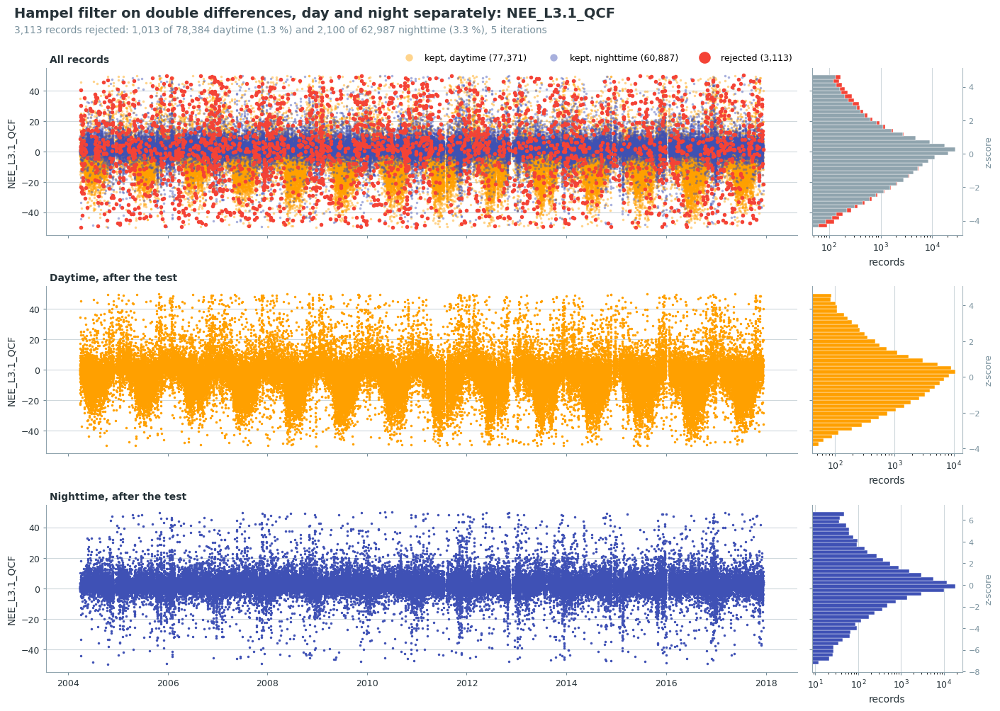

In [15]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [16]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2829 (  2.05%) | Day:  1109 | Night:  1720

[Dt/Nt] ITER #02 | Outliers:   319 (  0.24%) | Day:   122 | Night:   197

[Dt/Nt] ITER #03 | Outliers:    43 (  0.03%) | Day:    16 | Night:    27

[Dt/Nt] ITER #04 | Outliers:     4 (  0.00%) | Day:     2 | Night:     2

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 910 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

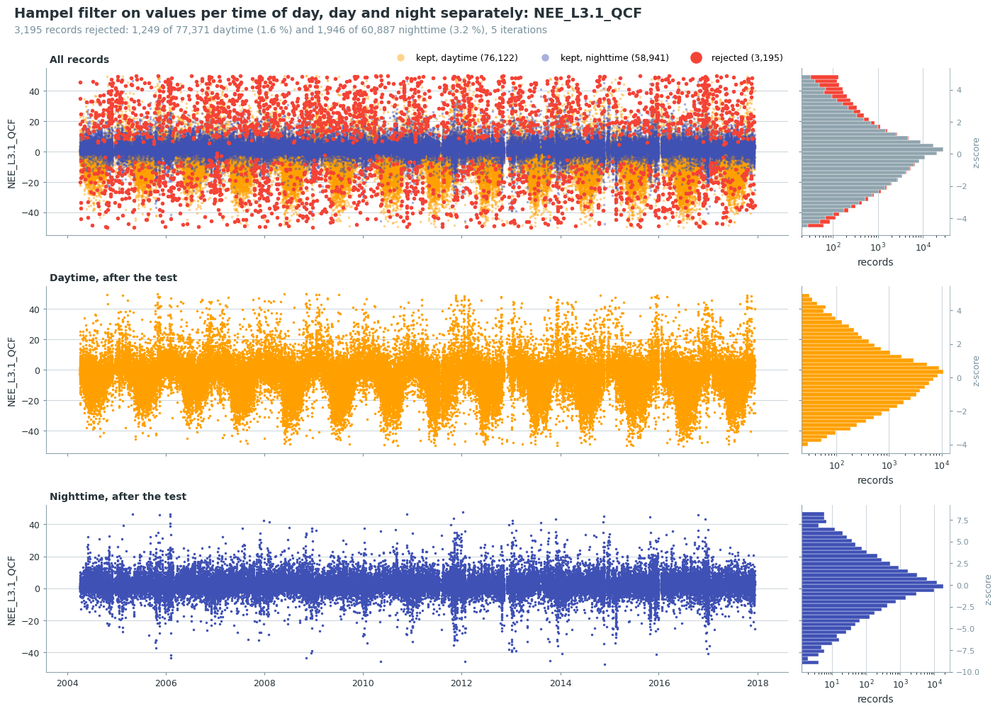

In [17]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [18]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day, 31 days

[Dt/Nt] ITER #01 | Outliers:   296 (  0.22%) | Day:   103 | Night:   193

[Dt/Nt] ITER #02 | Outliers:    17 (  0.01%) | Day:     8 | Night:     9

[Dt/Nt] ITER #03 | Outliers:     3 (  0.00%) | Day:     1 | Night:     2

[Dt/Nt] ITER #04 | Outliers:     1 (  0.00%) | Day:     0 | Night:     1

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 32 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

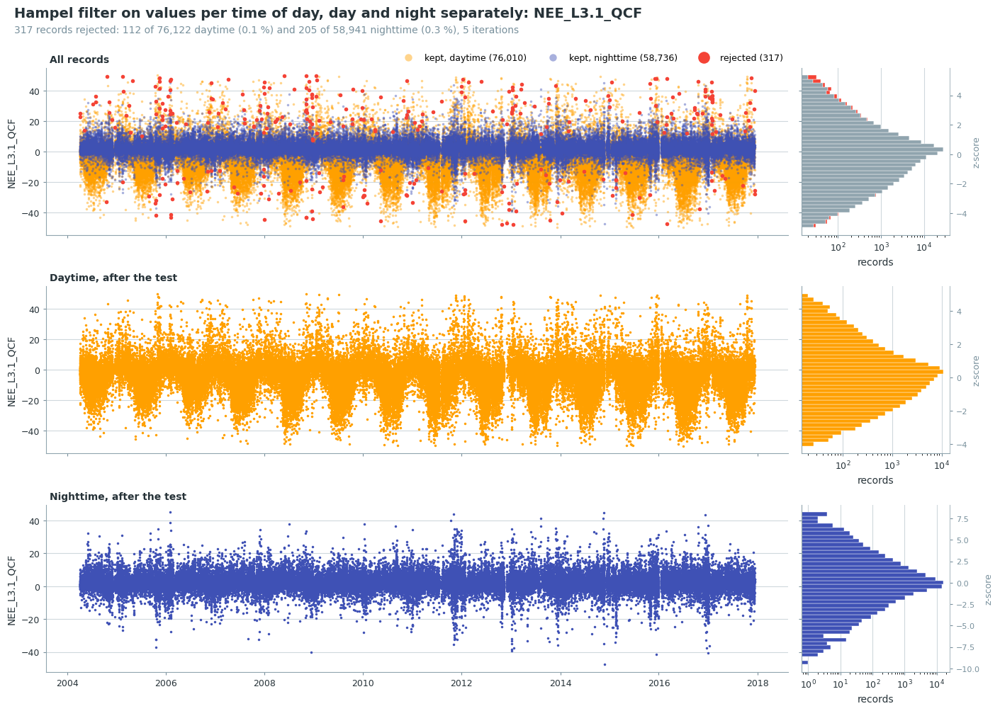

In [19]:
# The same test over 31 days at 7 sigma. It judges the records that the 13-day window above cannot
# test (fewer than 10 values, mostly sparse winter nights) and extreme values among a few noisy days,
# against a month of the same time of day.
sod.flag_outliers_hampel_test(window_length=48 * 31, n_sigma=7, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [20]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_3_TEST to flag data

### Negative values at night

At night the flux is respiration, so its true value is zero or above, and only random error pushes
it below zero. Test 5 removes only the values this error cannot explain: nighttime values below
`-NIGHT_Z` times their uncertainty `NIGHT_UNC`. `NIGHT_UNC` is the larger of the EddyPro random
uncertainty `FS` of the record and the median `PAS20` uncertainty (ONEFlux) of the nighttime
records of the same calendar month over all years, combined in quadrature with the uncertainty of
the opco correction, `OPCO_SIGMA`. `FS` covers only the sampling error of the covariance and is too
small on its own. `PAS20` covers the total random error, but in a noisy stretch, e.g. in fog on the
windows, the bad values widen it and pass the test; the monthly median does not grow with them.
With `NIGHT_Z = 4`, a random error of the shape of eddy-covariance errors (Laplace) exceeds the
limit with a probability of at most 0.2 % per record, a Gaussian one with 0.003 %. High values are
not tested ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#negative-nighttime)).

### 📋 Table: random uncertainty of the nighttime records

In [21]:
sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=TA_F, vpd=VPD_F, swin=SW_IN_F)

# Uncertainty of each record for tests 5 and 6: the larger of FS and the median PAS20 of the
# nighttime records of the same calendar month, over all years, combined in quadrature with the
# uncertainty of the opco correction (see Settings).
_night = (data.fpc_df['NIGHTTIME'].reindex(sigma.index) == 1) & sigma['PAS20'].notna()
_pas20_month = sigma.loc[_night, 'PAS20'].groupby(sigma.index[_night].month).median()
_pas20_typical = (pd.Series(sigma.index.month, index=sigma.index).map(_pas20_month)
                  .where(sigma['PAS20'].notna()))
night_unc = np.sqrt(np.fmax(sigma['FS'], _pas20_typical) ** 2 + OPCO_SIGMA ** 2).rename('NIGHT_UNC')
print(f"Median PAS20 of the nighttime records per calendar month ({FLUX_UNITS}): "
      + ", ".join(f"{_m}: {_v:.2f}" for _m, _v in _pas20_month.items()))
print(f"NIGHT_UNC, median at night: {night_unc[_night].median():.2f} {FLUX_UNITS}")

Random uncertainty of the 58,736 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.92   8,203 (14.0 %)    5,449 (9.3 %)
PAS20                    3.90      825 (1.4 %)       84 (0.1 %)
MAX                      3.94      649 (1.1 %)       45 (0.1 %)
POOLED                   3.16    2,025 (3.4 %)      962 (1.6 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two. POOLED: spread of all nighttime values within 15 days
on either side.

Median PAS20 of the nighttime records per calendar month (µmol m-2 s-1): 1: 4.57, 2: 3.96, 3: 3.16, 4: 3.23, 5: 3.84, 6: 3.76, 7: 3.86, 8: 3.96, 9: 3.56, 10: 4.13, 11: 4.58, 12: 5.04
NIGHT_UNC, median at night: 4.08 µmol m-2 s-1


### 📊 Plot: nighttime values clearly below zero

> Nighttime records below -4 uncertainties: 96. Expected from noise alone (Gaussian): 0.5 records,
raising the sum by 9.95 (flux units x records) once their gaps are filled.

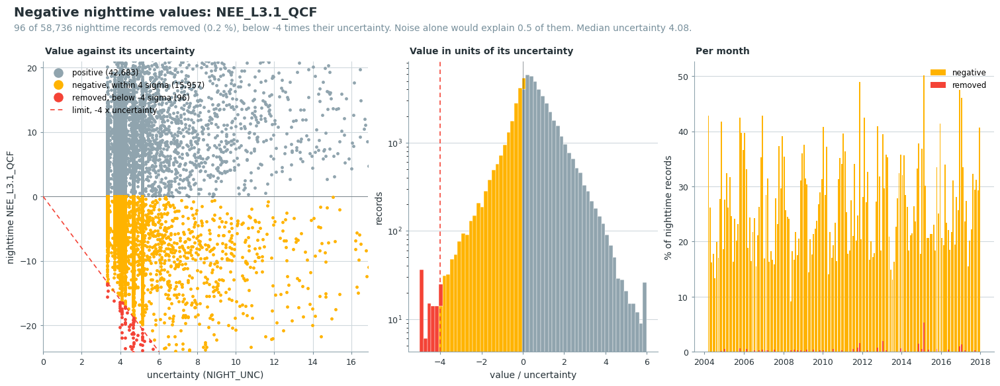

In [22]:
sod.flag_outliers_negative_night_test(uncertainty=night_unc, z=NIGHT_Z, showplot=True, verbose=True)

In [23]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

### Nights shifted below zero

Test 5 tests each record on its own and lets through a night that is shifted below zero as a whole: in fog or rime on the open-path windows the LI-7500 reads uptake for hours, each record within a few uncertainties of zero. Test 6 removes every record of a night whose median lies below `-NIGHTS_Z` standard errors of that median. The standard error combines two parts in quadrature. The random part is √(π/2) times the median `NIGHT_UNC` of the night over √n, with n reduced to the number of independent records, n (1 − r) / (1 + r), for the lag-1 autocorrelation r = `NIGHTS_AUTOCORR` of the nighttime values. The second part is `OPCO_SIGMA`: an error of the opco correction is shared by the records of a night and does not average out. With `NIGHTS_Z = 3` the test removes clearly wrong nights, not slightly negative ones. Nights with fewer than `NIGHTS_MIN_RECORDS` values are not tested ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#negative-nights)).

### 📊 Plot: nights shifted below zero

Lag-1 autocorrelation of the nighttime values about their night median: 0.18 (NIGHTS_AUTOCORR = 0.2)


> Nights with a median below -3 standard errors: 18 of 3,897 tested nights, 318 records.

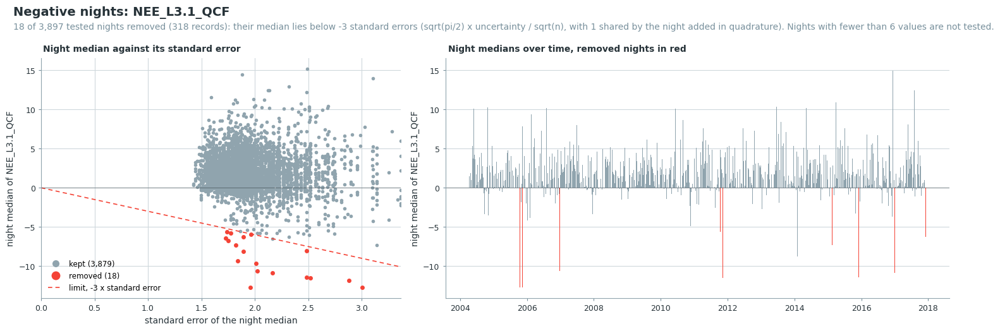

In [24]:
# Check of NIGHTS_AUTOCORR: lag-1 autocorrelation of the nighttime values about their night median.
_s = sod.series_hires_cleaned
_v = _s[(data.fpc_df['NIGHTTIME'].reindex(_s.index) == 1) & _s.notna()]
_dev = _v - _v.groupby(night_of(_v.index)).transform('median')
_r = _dev.corr(_dev.groupby(night_of(_dev.index)).shift(1))
print(f"Lag-1 autocorrelation of the nighttime values about their night median: {_r:.2f} "
      f"(NIGHTS_AUTOCORR = {NIGHTS_AUTOCORR})")
# Widening the record uncertainty by sqrt((1 + r) / (1 - r)) gives the standard error of
# n (1 - r) / (1 + r) independent records.
_nights_unc = (night_unc * np.sqrt((1 + NIGHTS_AUTOCORR) / (1 - NIGHTS_AUTOCORR))).rename('NIGHT_UNC')
sod.flag_outliers_negative_nights_test(uncertainty=_nights_unc, z=NIGHTS_Z, min_records=NIGHTS_MIN_RECORDS,
                                       systematic=OPCO_SIGMA, showplot=True, verbose=True)

In [25]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHTS_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [26]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test',
         'flag_outliers_negative_night_test',
         'flag_outliers_negative_nights_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,yes
sod.flag_outliers_negative_nights_test(),Flag all records of nights whose median lies b...,yes


### Apply the Level-3.2 flags

In [27]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 134,332 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

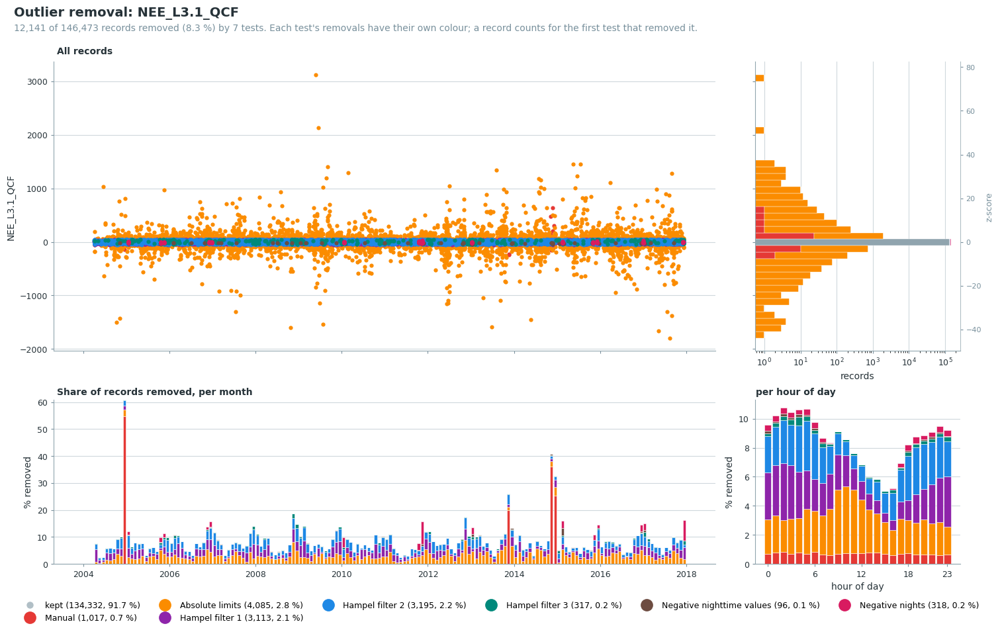

In [28]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

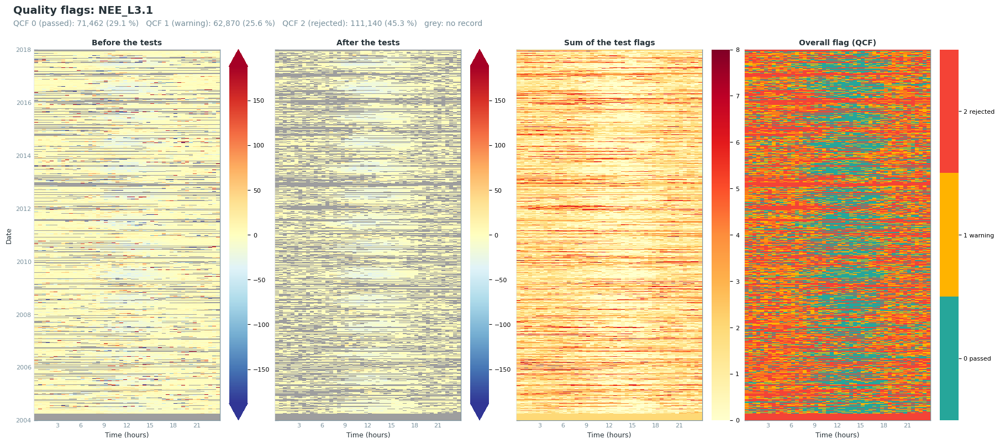

In [29]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [30]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: NEE_L3.1
Measured records: 197,858 of 245,472
Missing records: 47,614 (19.40 %), flagged by the missing-values test
                                                            Pass     Warn     Fail    Fail      Not
Test                                  Period    Tested       (0)      (1)      (2)       %   tested
───────────────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                           all      197,858    77,044   79,063   41,751   21.10        0
                                      day      100,481    51,863   33,888   14,730   14.66        0
                                      night     97,377    25,181   45,175   27,021   27.75        0
                                                                                                   
L2_FC_SCF                             all      197,858   197,858        0        0    0.00        0
                                      day      100,481   100,481        0        0    0.00        0
                                      night     97,377    97,377        0        0    0.00        0
                                                                                                   
L2_FC_SIGNAL_STRENGTH                 all      197,858   185,670        0   12,188    6.16        0
                                      day      100,481    94,860        0    5,621    5.59        0
                                      night     97,377    90,810        0    6,567    6.74        0
                                                                                                   
L2_FC_CO2_VM97_SPIKE_HF               all      197,858   195,048        0    2,810    1.42        0
                                      day      100,481    99,266        0    1,215    1.21        0
                                      night     97,377    95,782        0    1,595    1.64        0
                                                                                                   
L2_FC_CO2_VM97_DROPOUT_HF             all      197,858   197,858        0        0    0.00        0
                                      day      100,481   100,481        0        0    0.00        0
                                      night     97,377    97,377        0        0    0.00        0
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_MANUAL      all      146,473   145,456        0    1,017    0.69   51,385
                                      day       81,371    80,949        0      422    0.52   19,110
                                      night     65,102    64,507        0      595    0.91   32,275
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_ABSLIM      all      145,456   141,371        0    4,085    2.81   52,402
                                      day       80,949    78,384        0    2,565    3.17   19,532
                                      night     64,507    62,987        0    1,520    2.36   32,870
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL      all      141,371   138,258        0    3,113    2.20   56,487
                                      day       78,384    77,371        0    1,013    1.29   22,097
                                      night     62,987    60,887        0    2,100    3.33   34,390
                                                                                                   
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2    all      138,258   135,063        0    3,195    2.31   59,600
                                      day       77,371    76,122        0    1,249    1.61   23,110
                                      night     60,887    58,941        0    1,946    3.20   36,490
                                                                        

## Step 5: USTAR filter (Level 3.3)

Removes records with USTAR below the threshold, by day and by night; unlike ONEFlux, the first
record above it is kept. One scenario per threshold in `USTAR_THRESHOLDS`
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [31]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_16

> QCF computed for USTAR scenario CUT_50

> QCF computed for USTAR scenario CUT_84

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records per USTAR scenario

In [32]:
report_gapfilling_input(data);

Records for gap-filling
                    removed:   removed:             used:    used:    used:    used:
USTAR    measured      tests      USTAR     used    QCF 0    QCF 1      day    night
────────────────────────────────────────────────────────────────────────────────────
CUT_16    197,858     63,526     44,762   89,570   56,793   32,777   56,699   32,871
              81%        26%        18%      36%      23%      13%      23%      13%
CUT_50    197,858     63,526     66,514   67,818   45,021   22,797   43,919   23,899
              81%        26%        27%      28%      18%       9%      18%      10%
CUT_84    197,858     63,526     85,273   49,059   33,665   15,394   32,297   16,762
              81%        26%        35%      20%      14%       6%      13%       7%
Records, and their share of all 245,472 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

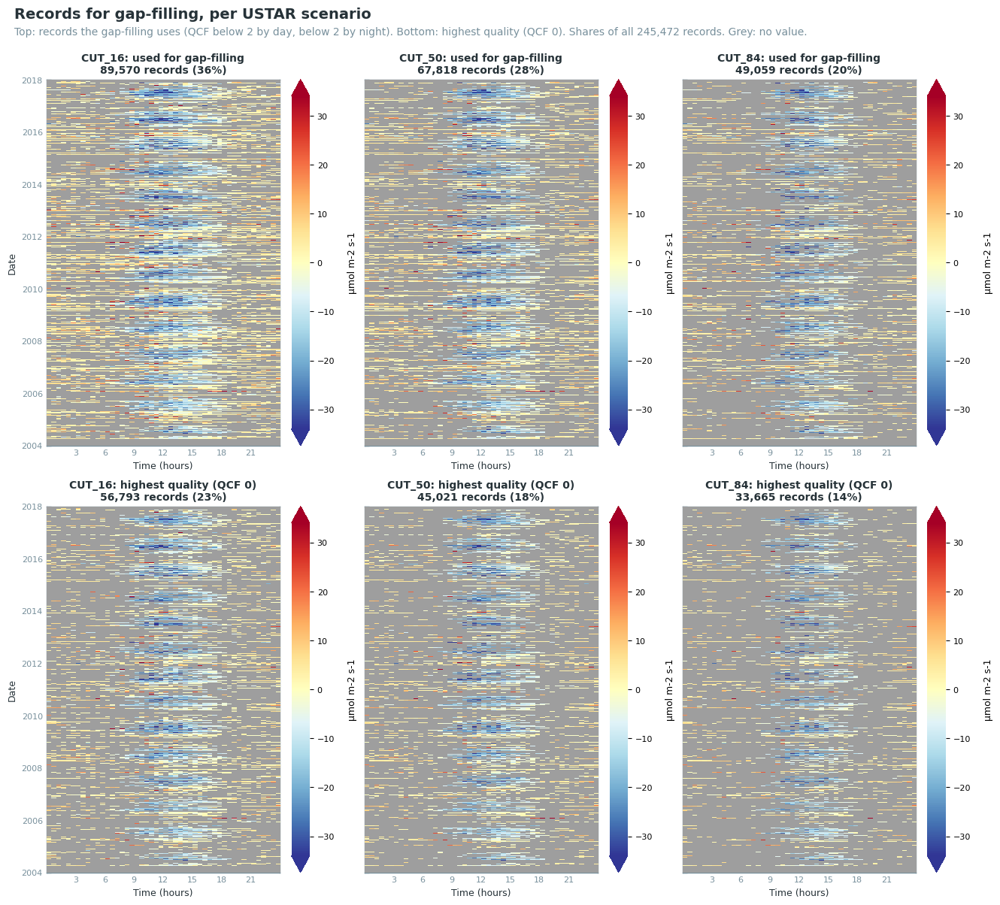

In [33]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📊 Plot: time series of the records for gap-filling and highest-quality records

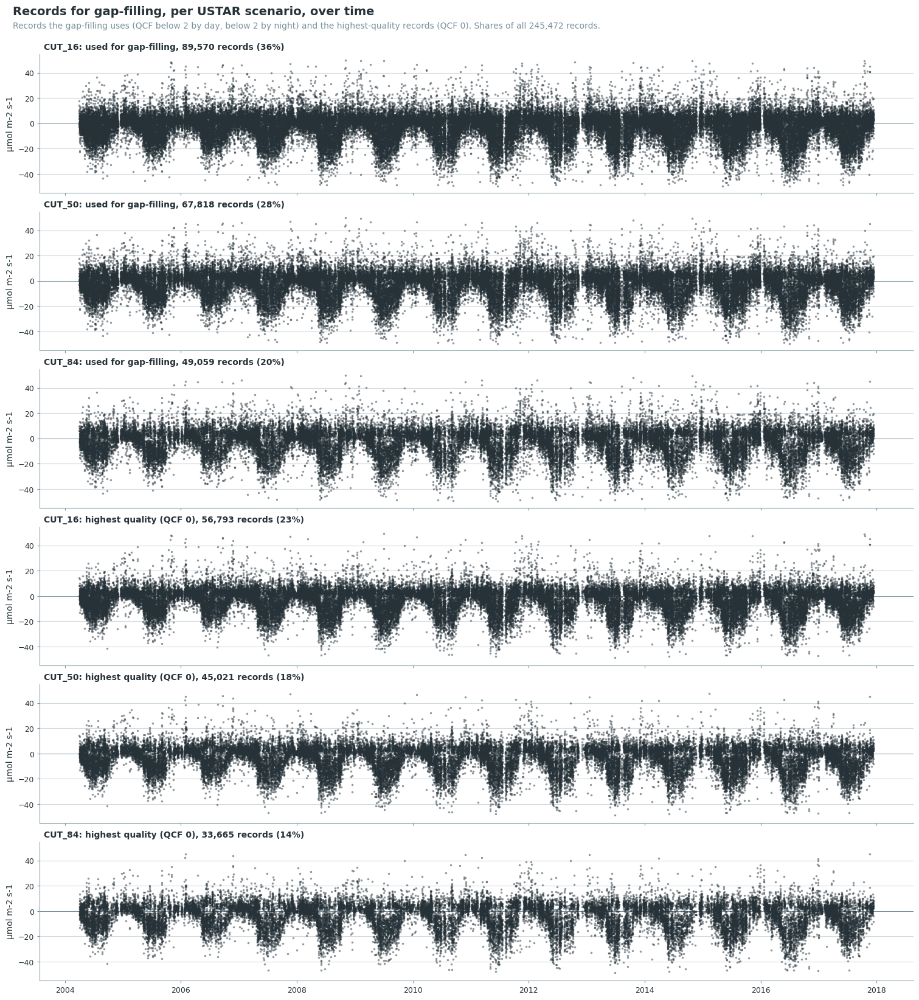

In [34]:
plot_gapfilling_input_timeseries(data, units=FLUX_UNITS)

### 📋 Table: gaps per USTAR scenario

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [35]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR    missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
─────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16        63.5   23026         362                 90.5           Jan                    73.3
CUT_50        72.4   19141         553                 90.5           Jan                    80.4
CUT_84        80.0   15787         772                 90.5           Jan                    85.9
A long gap lasts at least 1 day.

## Step 6: meteo drivers and model features

The ONEFlux partitioning needs measured temperature and radiation. These are the complete driver
series, restricted to the measured records. `add_driver` puts them into `data.full_df`,
where Levels 4.1 and 4.2 look for their drivers.

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [36]:
_ta_meas = df[TA_F].where(df[TA_FLAG] == 0).rename(TA_MEAS)
_sw_meas = df[SW_IN_F].where(df[SW_IN_FLAG] == 0).rename(SW_IN_MEAS)
data = add_driver(data, _ta_meas)
data = add_driver(data, _sw_meas)
print(f"{TA_MEAS}: {_ta_meas.notna().sum():,} measured records of {len(_ta_meas):,}")
print(f"{SW_IN_MEAS}: {_sw_meas.notna().sum():,} measured records of {len(_sw_meas):,}")

engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

TA_T1_47_1_HOMOGENIZED_MEASURED: 229,684 measured records of 245,472
SW_IN_T1_47_1_MEASURED: 212,319 measured records of 245,472


## Step 7: gap-filling (Level 4.1)

The gaps of this dataset are filled with XGBoost, and its wet night gaps from a Lloyd-Taylor model
(`PRODUCT_FILL`, columns `_gfXGWN`, below). Plain XGBoost and MDS are kept for comparison (Step 11).

### XGBoost

One model per year and USTAR scenario, trained on three years, with features selected by SHAP and
shared across the scenarios ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [37]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 1 of 14 (2004), 0 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 3 of 14 (2006), 31 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 5 of 14 (2008), 1 min 04 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 7 of 14 (2010), 1 min 37 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 9 of 14 (2012), 2 min 10 s so far

... (35 outputs left out)

v Training and gap-filling, NEE_L3.1_L3.3_CUT_50_QCF: 14 of 14 done in 35 s

> Training and gap-filling, NEE_L3.1_L3.3_CUT_84_QCF: step 1 of 14 (2004), 0 s so far

> Training and gap-filling, NEE_L3.1_L3.3_CUT_84_QCF: step 14 of 14 (2017), 30 s so far

v Training and gap-filling, NEE_L3.1_L3.3_CUT_84_QCF: 14 of 14 done in 32 s

### XGBoost with Lloyd-Taylor for the wet nights

The LI-7500 cannot measure in rain and fog, and XGBoost fills these night gaps too low. This fill
takes XGBoost for all gaps and fills the wet night gaps from a Lloyd-Taylor model on the dry measured
nights of each year ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#wetnight-gapfilling)).
Its columns end in `_gfXGWN`, next to the plain XGBoost fill (`_gfXG`). Wet and dry are defined under
Settings (`WETNIGHT_*`).

**Skipped** when `RUN_WETNIGHT = False`.

In [38]:
if RUN_WETNIGHT:
    _met = pd.read_parquet(METEOFILE, columns=[PREC, LW_IN]).reindex(df.index)
    _rain = _met[PREC].rolling(2 * WETNIGHT_RAIN_HOURS, min_periods=1).sum() > 0
    _wet_window = df['CUSTOM_AGC_IRGA75_MEAN'] >= WETNIGHT_AGC_MIN
    _after = df.index >= pd.Timestamp(LW_CHANGE)
    _q05, _q95 = np.where(_after, LWR_Q05[1], LWR_Q05[0]), np.where(_after, LWR_Q95[1], LWR_Q95[0])
    _ci = (_met[LW_IN] / (5.670374e-8 * (df[TA_F] + 273.15) ** 4) - _q05) / (_q95 - _q05)
    WET = (_rain | _wet_window | (_ci >= WETNIGHT_CI_MIN)).rename('WET')
    DRY = (~_rain & ~_wet_window).rename('DRY')
    data = run_level41_xgb_wetnight(
        data,
        features=FEATURES,
        engineer=engineer,
        wet=WET,
        dry=DRY,
        ta=TA_F,
        reduce_features=True,
        n_estimators_cv=True,
        verbose=1,
        **XGB_SETTINGS,
    )
    for _scen, _inst in data.levels.level41_xgbwn.items():
        print(f"{_scen}: {_inst.n_wetnight_filled_:,} wet night gaps filled from the Lloyd-Taylor model")

────────────────── Level 4.1: Gap-Filling (XGBoost, Lloyd-Taylor for wet nights) ───────────────────

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 1 of 14 (2004), 0 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 3 of 14 (2006), 33 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 5 of 14 (2008), 1 min 07 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 7 of 14 (2010), 1 min 41 s so far

> Feature reduction, NEE_L3.1_L3.3_CUT_16_QCF: step 9 of 14 (2012), 2 min 17 s so far

... (31 outputs left out)

v Training and gap-filling, NEE_L3.1_L3.3_CUT_50_QCF: 14 of 14 done in 36 s

> Training and gap-filling, NEE_L3.1_L3.3_CUT_84_QCF: step 1 of 14 (2004), 0 s so far

v Training and gap-filling, NEE_L3.1_L3.3_CUT_84_QCF: 14 of 14 done in 31 s

CUT_16: 43,128 wet night gaps filled from the Lloyd-Taylor model
CUT_50: 45,287 wet night gaps filled from the Lloyd-Taylor model
CUT_84: 46,958 wet night gaps filled from the Lloyd-Taylor model


### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [39]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: partitioning into GPP and RECO (Level 4.2)

**Skipped** when `RUN_PARTITIONING = False`. Nighttime and daytime partitioning as in ONEFlux
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#partitioning)),
on the gap-filled `NEE` of the product fill (`PRODUCT_FILL`).

In [40]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='nighttime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        gapfill_method=PRODUCT_FILL,
    )

───────────────── Level 4.2: NEE Partitioning (Nighttime ONEFlux, Reichstein 2005) ─────────────────

F:\dev\diive\diive\flux\partitioning\nighttime_oneflux.py:211: RuntimeWarning: overflow encountered in cast
  rref, e0 = (temp.dtype.type(p) for p in par)
F:\dev\diive\diive\flux\partitioning\nighttime_oneflux.py:92: RuntimeWarning: invalid value encountered in multiply
  return rref * np.exp(e0 * ((1.0 / (tref - t0)) - (1.0 / (ta - t0))))


In [41]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='daytime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        sw_in_f=SW_IN_F,
        vpd_f=VPD_F,  # kPa
        gapfill_method=PRODUCT_FILL,
    )
    print(data.partitioned_cols())

─────────────────── Level 4.2: NEE Partitioning (Daytime ONEFlux, Lasslop 2010) ────────────────────

! Daytime partitioning (ONEFlux): no light-response curve could be fitted; year left 
unpartitioned.

! Daytime partitioning (ONEFlux): no light-response curve could be fitted; year left 
unpartitioned.

! Daytime partitioning (ONEFlux): no light-response curve could be fitted; year left 
unpartitioned.

! Daytime partitioning (ONEFlux): HLRC_LloydVPD fit failed in the window of days 68-80 of NEE 
series 'CUT_84'; measured NEE there removed in all series and the year partitioned again, as ONEFlux
does.

{'nt_of': {'CUT_16': ['NEE_NIGHT_OF_CUT_16', 'RECO_NT_OF_CUT_16', 'RECO_NT_OF_ROB_CUT_16', 'GPP_NT_OF_CUT_16', 'GPP_NT_OF_ROB_CUT_16', 'RREF_NT_OF_CUT_16', 'E0_NT_OF_CUT_16'], 'CUT_50': ['NEE_NIGHT_OF_CUT_50', 'RECO_NT_OF_CUT_50', 'RECO_NT_OF_ROB_CUT_50', 'GPP_NT_OF_CUT_50', 'GPP_NT_OF_ROB_CUT_50', 'RREF_NT_OF_CUT_50', 'E0_NT_OF_CUT_50'], 'CUT_84': ['NEE_NIGHT_OF_CUT_84', 'RECO_NT_OF_CUT_84', 'RECO_NT_OF_ROB_CUT_84', 'GPP_NT_OF_CUT_84', 'GPP_NT_OF_ROB_CUT_84', 'RREF_NT_OF_CUT_84', 'E0_NT_OF_CUT_84']}, 'dt_of': {'CUT_16': ['RECO_DT_OF_CUT_16', 'GPP_DT_OF_CUT_16', 'SE_GPP_DT_OF_CUT_16', 'ALPHA_DT_OF_CUT_16', 'BETA_DT_OF_CUT_16', 'K_DT_OF_CUT_16', 'RREF_DT_OF_CUT_16', 'E0_DT_OF_CUT_16'], 'CUT_50': ['RECO_DT_OF_CUT_50', 'GPP_DT_OF_CUT_50', 'SE_GPP_DT_OF_CUT_50', 'ALPHA_DT_OF_CUT_50', 'BETA_DT_OF_CUT_50', 'K_DT_OF_CUT_50', 'RREF_DT_OF_CUT_50', 'E0_DT_OF_CUT_50'], 'CUT_84': ['RECO_DT_OF_CUT_84', 'GPP_DT_OF_CUT_84', 'SE_GPP_DT_OF_CUT_84', 'ALPHA_DT_OF_CUT_84', 'BETA_DT_OF_CUT_84', 'K_DT_OF_CU

The daytime method fits its light response only on records with measured `SW_IN`, which starts
on 14 September 2005. Before that date no window can be fitted, and the method takes the
parameters of the first fitted windows and applies them to modelled light. These values are set
to missing (`DT_VALID_FROM`). The nighttime method fits on nighttime `NEE` and air temperature and
is kept.

In [42]:
if RUN_PARTITIONING:
    _first = data.full_df[SW_IN_MEAS].first_valid_index()
    assert _first is None or _first == pd.Timestamp(DT_VALID_FROM), \
        f"first measured {SW_IN_MEAS} is {_first}, not DT_VALID_FROM"
    DT_COLS = [c for cols in data.partitioned_cols().get('dt_of', {}).values() for c in cols]
    _before = data.fpc_df.index < pd.Timestamp(DT_VALID_FROM)
    print(f"Daytime partitioning: {data.fpc_df.loc[_before, DT_COLS].notna().any(axis=1).sum():,} "
          f"half-hours of {len(DT_COLS)} columns set to missing before {DT_VALID_FROM}")
    data.fpc_df.loc[_before, DT_COLS] = np.nan

Daytime partitioning: 12,310 half-hours of 24 columns set to missing before 2005-09-14 11:15


## Step 9: results

How many records were measured and how many were filled, then the annual sum of the flux, for each
USTAR scenario. The share measured is given in brackets: a year with long gaps rests largely on the
model. An incomplete year is marked.

### 📋 Table: measured and filled records

In [43]:
report_gapfilling_variables(data)

Gap-filled variables
method                             USTAR    records   measured    filled   filled %
───────────────────────────────────────────────────────────────────────────────────
MDS                                CUT_16   245,472     89,570   155,902       63.5
MDS                                CUT_50   245,472     67,818   177,654       72.4
MDS                                CUT_84   245,472     49,059   196,413       80.0
XGBoost                            CUT_16   245,472     89,570   155,902       63.5
XGBoost                            CUT_50   245,472     67,818   177,654       72.4
XGBoost                            CUT_84   245,472     49,059   196,413       80.0
XGBoost, Lloyd-Taylor wet nights   CUT_16   245,472     89,570   155,902       63.5
XGBoost, Lloyd-Taylor wet nights   CUT_50   245,472     67,818   177,654       72.4
XGBoost, Lloyd-Taylor wet nights   CUT_84   245,472     49,059   196,413       80.0
MDS (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfMDS
MDS (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfMDS
MDS (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfMDS
XGBoost (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfXG
XGBoost (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfXG
XGBoost (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfXG
XGBoost, Lloyd-Taylor wet nights (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> 
NEE_L3.1_L3.3_CUT_16_QCF_gfXGWN
XGBoost, Lloyd-Taylor wet nights (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> 
NEE_L3.1_L3.3_CUT_50_QCF_gfXGWN
XGBoost, Lloyd-Taylor wet nights (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> 
NEE_L3.1_L3.3_CUT_84_QCF_gfXGWN

### 📋 Table: annual sums of the flux

In [44]:
report_annual_sums(data, gain=UMOL_TO_GC, units='gC m-2');

Annual sums (gC m-2)
              MDS          MDS         MDS      XGBoost      XGBoost      XGBoost   XGBoost, Lloyd-Taylor wet nights   XGBoost, Lloyd-Taylor wet nights   XGBoost, Lloyd-Taylor wet nights
year       CUT_16       CUT_50      CUT_84       CUT_16       CUT_50       CUT_84                             CUT_16                             CUT_50                             CUT_84
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
2004     14 (29%)      9 (23%)    75 (17%)    147 (29%)    198 (23%)    170 (17%)                          205 (29%)                          257 (23%)                          284 (17%)
2005    112 (35%)    186 (26%)   183 (18%)    143 (35%)    212 (26%)    174 (18%)                          199 (35%)                          276 (26%)                          298 (18%)
2006    369 (37%)    519 (28%)   535 (19%)    202 (37%)    333 (28%)    286 (19%)                          310 (37%)                          450 (28%)                          437 (19%)
2007     30 (40%)     87 (31%)   162 (22%)    -27 (40%)     25 (31%)     91 (22%)                           62 (40%)                          120 (31%)                          202 (22%)
2008     41 (40%)    122 (31%)   238 (23%)    -47 (40%)     51 (31%)    155 (23%)                           37 (40%)                          139 (31%)                          234 (23%)
2009     -4 (37%)    134 (27%)   253 (19%)    -49 (37%)     31 (27%)    129 (19%)                            2 (37%)                           94 (27%)                          191 (19%)
2010    -40 (35%)     -8 (26%)    33 (19%)   -148 (35%)    -98 (26%)    -23 (19%)                          -29 (35%)                           30 (26%)                          117 (19%)
2011   -239 (38%)   -129 (29%)    15 (21%)   -273 (38%)   -157 (29%)    -29 (21%)                         -122 (38%)                            7 (29%)                          135 (21%)
2012   -247 (33%)   -186 (24%)    45 (18%)   -213 (33%)   -174 (24%)    -68 (18%)                          -94 (33%)                          -40 (24%)                           51 (18%)
2013    -16 (36%)     10 (28%)    35 (21%)   -146 (36%)   -114 (28%)   -106 (21%)                          -84 (36%)                          -43 (28%)                          -28 (21%)
2014   -104 (37%)     29 (28%)   207 (20%)   -201 (37%)   -119 (28%)     12 (20%)                         -109 (37%)                          -10 (28%)                          120 (20%)
2015   -214 (39%)    -82 (30%)    -8 (23%)   -209 (39%)    -47 (30%)     50 (23%)                         -174 (39%)                           -9 (30%)                           82 (23%)
2016   -198 (38%)    -71 (28%)     5 (20%)   -332 (38%)   -233 (28%)   -160 (20%)                         -246 (38%)                         -145 (28%)                          -47 (20%)
2017    -81 (36%)     26 (27%)    95 (19%)   -174 (36%)    -72 (27%)    -14 (19%)                         -118 (36%)                          -16 (27%)                           49 (19%)
In brackets: the share of the year's records that were measured.

## Step 10: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [45]:
report_traintest_model_scores(data)

Held-out test scores
method                             USTAR    year      R²   RMSE    MAE   MedAE   MaxE
─────────────────────────────────────────────────────────────────────────────────────
XGBoost                            CUT_16   2004   0.582   5.80   3.87    2.47   43.7
XGBoost                            CUT_16   2005   0.582   5.80   3.87    2.47   43.7
XGBoost                            CUT_16   2006   0.603   5.96   3.96    2.53   46.3
XGBoost                            CUT_16   2007   0.610   6.13   4.02    2.51   48.2
XGBoost                            CUT_16   2008   0.636   6.29   4.11    2.50   47.5
XGBoost                            CUT_16   2009   0.644   6.27   4.16    2.61   45.0
XGBoost                            CUT_16   2010   0.640   6.43   4.28    2.72   42.6
XGBoost                            CUT_16   2011   0.627   6.53   4.34    2.77   43.1
XGBoost                            CUT_16   2012   0.610   6.82   4.50    2.79   40.1
XGBoost                            CUT_16   2013   0.598   6.92   4.62    2.89   42.5
XGBoost                            CUT_16   2014   0.587   7.02   4.67    2.93   44.8
XGBoost                            CUT_16   2015   0.612   6.99   4.67    3.01   46.3
XGBoost                            CUT_16   2016   0.630   6.79   4.56    2.97   43.5
XGBoost                            CUT_16   2017   0.630   6.79   4.56    2.97   43.5
XGBoost                            CUT_16   mean   0.614   6.47   4.30    2.72   44.3
                                                                                     
XGBoost                            CUT_50   2004   0.610   5.87   3.90    2.57   44.3
XGBoost                            CUT_50   2005   0.610   5.87   3.90    2.57   44.3
XGBoost                            CUT_50   2006   0.631   6.04   4.00    2.62   46.1
XGBoost                            CUT_50   2007   0.647   6.13   4.02    2.58   48.4
XGBoost                            CUT_50   2008   0.673   6.24   4.12    2.62   47.8
XGBoost                            CUT_50   2009   0.680   6.18   4.16    2.64   44.3
XGBoost                            CUT_50   2010   0.674   6.40   4.29    2.71   39.3
XGBoost                            CUT_50   2011   0.662   6.46   4.33    2.82   37.3
XGBoost                            CUT_50   2012   0.643   6.79   4.52    2.81   41.0
XGBoost                            CUT_50   2013   0.634   6.82   4.57    2.86   38.6
XGBoost                            CUT_50   2014   0.612   7.03   4.68    2.94   45.4
XGBoost                            CUT_50   2015   0.636   6.98   4.65    2.96   45.2
XGBoost                            CUT_50   2016   0.663   6.65   4.51    3.00   44.9
XGBoost                            CUT_50   2017   0.663   6.65   4.51    3.00   44.9
XGBoost                            CUT_50   mean   0.645   6.44   4.30    2.76   43.7
                                                                                     
XGBoost                            CUT_84   2004   0.628   5.90   3.93    2.62   45.7
XGBoost                            CUT_84   2005   0.628   5.90   3.93    2.62   45.7
XGBoost                            CUT_84   2006   0.644   6.11   4.05    2.61   45.9
XGBoost                            CUT_84   2007   0.665   6.12   4.04    2.59   50.1
XGBoost                            CUT_84   2008   0.691   6.27   4.20    2.71   47.1
XGBoost                            CUT_84   2009   0.694   6.25   4.24    2.79   41.8
XGBoost                            CUT_84   2010   0.690   6.51   4.43    2.97   36.4
XGBoost                            CUT_84   2011   0.674   6.54   4.44    2.89   36.0
XGBoost                            CUT_84   2012   0.666   6.76   4.53    2.92   41.4
XGBoost                            CUT_84   2013   0.654   6.80   4.58    3.02   42.0
XGBoost                            CUT_84   2014   0.641   6.95   4.69    3.06   42.2
XGBoost                            CUT_84   2015   0.653   6.98   4.67    2.88   43.5
XGBoost                

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [46]:
report_model_overview(data);

Gap-filling models
                                                   trained                                          final    test   test            fall-
method                             USTAR    year   on          features    train    test   trees      fit      R²   RMSE   filled    back
─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
XGBoost                            CUT_16   2004   2004-2006         77   13,222   4,472      80   17,694   0.582   5.80   12,417       0
XGBoost                            CUT_16   2005   2004-2006         77   13,222   4,472      80   17,694   0.582   5.80   11,435       0
XGBoost                            CUT_16   2006   2005-2007         77   14,620   4,936      80   19,556   0.603   5.96   11,062       0
XGBoost                            CUT_16   2007   2006-2008         77   15,448   5,093      80   20,541   0.610   6.13   10,507       0
XGBoost                            CUT_16   2008   2007-2009         77   15,472   5,091      80   20,563   0.636   6.29   10,498       0
XGBoost                            CUT_16   2009   2008-2010         77   14,865   4,850      80   19,715   0.644   6.27   11,040       0
XGBoost                            CUT_16   2010   2009-2011         77   14,455   4,805      80   19,260   0.640   6.43   11,355       0
XGBoost                            CUT_16   2011   2010-2012         77   13,934   4,594      80   18,528   0.627   6.53   10,905       0
XGBoost                            CUT_16   2012   2011-2013         77   14,015   4,669      80   18,684   0.610   6.82   11,820       0
XGBoost                            CUT_16   2013   2012-2014         77   13,959   4,616      80   18,575   0.598   6.92   11,199       0
XGBoost                            CUT_16   2014   2013-2015         77   14,752   4,984      80   19,736   0.587   7.02   11,014       0
XGBoost                            CUT_16   2015   2014-2016         77   15,008   5,075      80   20,083   0.612   6.99   10,611       0
XGBoost                            CUT_16   2016   2015-2017         77   14,934   5,024      80   19,958   0.630   6.79   10,900       0
XGBoost                            CUT_16   2017   2015-2017         77   14,934   5,024      80   19,958   0.630   6.79   11,139       0
                                                                                                                                         
XGBoost                            CUT_50   2004   2004-2006         77   10,003   3,379      80   13,382   0.610   5.87   13,518       0
XGBoost                            CUT_50   2005   2004-2006         77   10,003   3,379      80   13,382   0.610   5.87   13,007       0
XGBoost                            CUT_50   2006   2005-2007         77   11,044   3,719      80   14,763   0.631   6.04   12,701       0
XGBoost                            CUT_50   2007   2006-2008         77   11,854   3,911      80   15,765   0.647   6.13   12,089       0
XGBoost                            CUT_50   2008   2007-2009         77   11,797   3,910      80   15,707   0.673   6.24   12,053       0
XGBoost                            CUT_50   2009   2008-2010         77   11,213   3,688      80   14,901   0.680   6.18   12,759       0
XGBoost                            CUT_50   2010   2009-2011         77   10,782   3,623      80   14,405   0.674   6.40   12,895       0
XGBoost                            CUT_50   2011   2010-2012         77   10,472   3,472      80   13,944   0.662   6.46   12,501       0
XGBoost                            CUT_50   2012   2011-2013         77   10,650   3,560      80   14,210   0.643   6.79   13,268       0
XGBoost                            CUT_50   2013   2012-2014         77   10,572   3,477      80   14,049   0.634   6.82   12,629       0
XGBoost                            CUT_50   2014   2013-2015         77   11,252   3,823      80   15,075   0.612   7

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [47]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2004-2006    10,003      6.16      4.22     0.574     5.87    0.610
2005-2007    11,044      6.40      4.36     0.565     6.04    0.631
2006-2008    11,854      6.59      4.44     0.579     6.13    0.647
2007-2009    11,797      6.46      4.38     0.629     6.24    0.673
2008-2010    11,213      6.43      4.40     0.642     6.18    0.680
2009-2011    10,782      6.69      4.60     0.634     6.40    0.674
2010-2012    10,472      7.10      4.80     0.602     6.46    0.662
2011-2013    10,650      7.54      5.10     0.584     6.79    0.643
2012-2014    10,572      7.47      5.07     0.580     6.82    0.634
2013-2015    11,252      7.49      5.12     0.568     7.03    0.612
2014-2016    11,308      7.46      5.07     0.585     6.98    0.636
2015-2017    11,228      7.07      4.85     0.610     6.65    0.663
80 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to 
1000 tested). USTAR scenario CUT_50.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

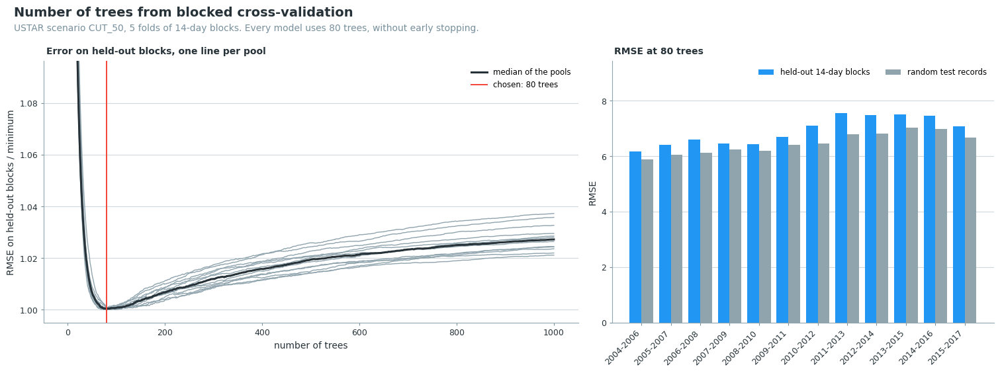

In [48]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [49]:
report_gapfilling_model_scores(data)

In-sample scores
method                             USTAR    year      R²   RMSE    MAE   MedAE   MaxE
─────────────────────────────────────────────────────────────────────────────────────
MDS                                CUT_16   all    0.524   7.23   4.86    3.13   67.6
MDS                                CUT_50   all    0.559   7.20   4.90    3.20   66.8
MDS                                CUT_84   all    0.576   7.28   4.98    3.29   55.0
XGBoost                            CUT_16   2004   0.686   5.09   3.50    2.35   34.7
XGBoost                            CUT_16   2005   0.686   5.09   3.50    2.35   34.7
XGBoost                            CUT_16   2006   0.686   5.28   3.59    2.38   42.2
XGBoost                            CUT_16   2007   0.702   5.36   3.62    2.38   44.7
XGBoost                            CUT_16   2008   0.726   5.38   3.65    2.38   44.2
XGBoost                            CUT_16   2009   0.738   5.36   3.66    2.42   43.0
XGBoost                            CUT_16   2010   0.732   5.54   3.80    2.51   38.1
XGBoost                            CUT_16   2011   0.717   5.76   3.92    2.58   36.0
XGBoost                            CUT_16   2012   0.706   6.05   4.11    2.68   44.2
XGBoost                            CUT_16   2013   0.694   6.11   4.16    2.70   47.0
XGBoost                            CUT_16   2014   0.683   6.17   4.21    2.77   47.6
XGBoost                            CUT_16   2015   0.696   6.16   4.21    2.77   46.2
XGBoost                            CUT_16   2016   0.715   5.88   4.05    2.69   49.1
XGBoost                            CUT_16   2017   0.715   5.88   4.05    2.69   49.1
XGBoost                            CUT_16   mean   0.706   5.65   3.86    2.55   42.9
                                                                                     
XGBoost                            CUT_50   2004   0.735   4.85   3.38    2.33   32.0
XGBoost                            CUT_50   2005   0.735   4.85   3.38    2.33   32.0
XGBoost                            CUT_50   2006   0.731   5.07   3.47    2.35   39.9
XGBoost                            CUT_50   2007   0.745   5.15   3.52    2.38   42.0
XGBoost                            CUT_50   2008   0.762   5.21   3.57    2.38   40.6
XGBoost                            CUT_50   2009   0.772   5.16   3.57    2.39   42.5
XGBoost                            CUT_50   2010   0.769   5.33   3.70    2.52   35.7
XGBoost                            CUT_50   2011   0.760   5.49   3.79    2.59   36.7
XGBoost                            CUT_50   2012   0.745   5.86   4.02    2.69   41.7
XGBoost                            CUT_50   2013   0.732   5.93   4.07    2.72   42.1
XGBoost                            CUT_50   2014   0.724   5.97   4.12    2.77   44.7
XGBoost                            CUT_50   2015   0.736   5.95   4.10    2.71   45.7
XGBoost                            CUT_50   2016   0.754   5.64   3.93    2.66   43.8
XGBoost                            CUT_50   2017   0.754   5.64   3.93    2.66   43.8
XGBoost                            CUT_50   mean   0.747   5.43   3.75    2.53   40.2
                                                                                     
XGBoost                            CUT_84   2004   0.778   4.58   3.24    2.31   32.4
XGBoost                            CUT_84   2005   0.778   4.58   3.24    2.31   32.4
XGBoost                            CUT_84   2006   0.768   4.85   3.37    2.29   35.8
XGBoost                            CUT_84   2007   0.780   4.91   3.40    2.31   36.8
XGBoost                            CUT_84   2008   0.795   5.00   3.48    2.38   37.2
XGBoost                            CUT_84   2009   0.804   4.93   3.47    2.39   43.3
XGBoost                            CUT_84   2010   0.799   5.17   3.64    2.53   32.1
XGBoost                            CUT_84   2011   0.788   5.32   3.72    2.58   35.3
XGBoost                            CUT_84   2012   0.777   5.65   3.91    2.65   35.9
XGBoost                    

### 📋 Table: years used to train each year's model

In [50]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2004         2004-2006              
2005         2004-2006              
2006         2005-2007              
2007         2006-2008              
2008         2007-2009              
2009         2008-2010              
2010         2009-2011              
2011         2010-2012              
2012         2011-2013              
2013         2012-2014              
2014         2013-2015              
2015         2014-2016              
2016         2015-2017              
2017         2015-2017              
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84) (does not pool years).

### 📋 Table: most important features (SHAP), CUT_16

In [51]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_16')

Feature importances, XGBoost (CUT_16): top 10 of 77 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.52   1.52   1.10   2.07   2.01   0.93   1.31   0.97   2.09   2.25   2.27   2.14   2.30   2.30   1.77
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2   1.00   1.00   0.60   0.71   0.98   1.41   1.40   0.58   1.04   1.26   2.10   2.54   2.01   2.01   1.33
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4   1.58   1.58   1.84   1.55   1.96   1.56   2.40   1.77   1.87   1.28   0.15   0.09   0.24   0.24   1.29
 4   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.92   0.92   0.82   0.37   0.67   0.35   0.56   0.62   0.60   0.57   0.78   1.05   1.15   1.15   0.75
 5   .HOUR_COS                      0.68   0.68   0.62   0.63   0.73   0.61   0.52   0.73   0.66   0.78   0.63   0.92   0.77   0.77   0.70
 6   SW_IN_T1_47_1_gfXG             0.35   0.35   0.51   1.15   1.17   0.46   0.06   0.07   0.20   0.38   0.54   0.50   0.73   0.73   0.51
 7   .WEEK_COS                      0.56   0.56   1.20   0.09   0.13   1.02   0.54   0.97   0.06   0.05   0.08   0.22   0.22   0.22   0.42
 8   .MONTH_SIN                     0.30   0.30   0.08   0.15   0.36   0.68   0.96   0.82   0.74   0.23   0.19   0.25   0.22   0.22   0.39
 9   .DOY_SIN                       0.62   0.62   0.37   0.33   0.17   0.19   0.11   0.32   0.33   0.37   0.40   0.35   0.45   0.45   0.36
10   .SW_IN_T1_47_1_gfXG_MEAN4      0.13   0.13   0.00   0.33   0.17   0.24   0.30   0.11   0.47   0.46   0.26   0.49   0.65   0.65   0.31

Feature importances, XGBoost, Lloyd-Taylor wet nights (CUT_16): top 10 of 77 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.52   1.52   1.10   2.07   2.01   0.93   1.31   0.97   2.09   2.25   2.27   2.14   2.30   2.30   1.77
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2   1.00   1.00   0.60   0.71   0.98   1.41   1.40   0.58   1.04   1.26   2.10   2.54   2.01   2.01   1.33
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4   1.58   1.58   1.84   1.55   1.96   1.56   2.40   1.77   1.87   1.28   0.15   0.09   0.24   0.24   1.29
 4   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.92   0.92   0.82   0.37   0.67   0.35   0.56   0.62   0.60   0.57   0.78   1.05   1.15   1.15   0.75
 5   .HOUR_COS                      0.68   0.68   0.62   0.63   0.73   0.61   0.52   0.73   0.66   0.78   0.63   0.92   0.77   0.77   0.70
 6   SW_IN_T1_47_1_gfXG             0.35   0.35   0.51   1.15   1.17   0.46   0.06   0.07   0.20   0.38   0.54   0.50   0.73   0.73   0.51
 7   .WEEK_COS                      0.56   0.56   1.20   0.09   0.13   1.02   0.54   0.97   0.06   0.05   0.08   0.22   0.22   0.22   0.42
 8   .MONTH_SIN                     0.30   0.30   0.08   0.15   0.36   0.68   0.96   0.82   0.74   0.23   0.19   0.25   0.22   0.22   0.39
 9   .DOY_SIN                       0.62   0.62   0.37   0.33   0.17   0.19   0.11   0.32   0.33   0.37   0.40   0.35   0.45   0.45   0.36
10   .SW_IN_T1_47_1_gfXG_MEAN4      0.13   0.13   0.00   0.33   0.17   0.24   0.30   0.11   0.47   0.46   0.26   0.49   0.65   0.65   0.31

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_16) (no model trained).

### 📋 Table: most important features (SHAP), CUT_50

In [52]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_50')

Feature importances, XGBoost (CUT_50): top 10 of 77 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.60   1.60   1.27   2.23   2.33   0.81   1.05   1.23   1.98   2.25   2.43   2.44   2.38   2.38   1.86
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2   1.46   1.46   0.52   1.00   1.45   1.29   0.72   0.55   1.36   1.93   2.17   2.41   1.29   1.29   1.35
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4   1.48   1.48   1.99   1.45   1.27   1.57   3.30   1.55   1.85   1.08   0.24   0.12   0.13   0.13   1.26
 4   SW_IN_T1_47_1_gfXG             0.31   0.31   0.75   1.58   1.78   0.60   0.17   0.09   0.32   0.34   0.67   0.70   0.87   0.87   0.67
 5   .HOUR_COS                      0.62   0.62   0.50   0.56   0.67   0.60   0.36   0.53   0.56   0.73   0.68   0.85   0.70   0.70   0.62
 6   .SW_IN_T1_47_1_gfXG_MEAN2      0.05   0.05   0.03   0.20   0.35   1.17   0.40   0.06   0.15   0.54   1.34   1.00   1.60   1.60   0.61
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.72   0.72   0.58   0.17   0.41   0.14   0.27   0.51   0.62   0.51   0.71   0.76   0.78   0.78   0.55
 8   .MONTH_SIN                     0.38   0.38   0.02   0.10   0.35   0.69   1.27   1.19   0.80   0.34   0.24   0.28   0.15   0.15   0.45
 9   .WEEK_COS                      0.52   0.52   1.33   0.13   0.12   1.21   0.71   0.62   0.23   0.03   0.11   0.13   0.26   0.26   0.44
10   .DOY_SIN                       0.68   0.68   0.35   0.44   0.16   0.19   0.19   0.26   0.43   0.44   0.39   0.40   0.59   0.59   0.41

Feature importances, XGBoost, Lloyd-Taylor wet nights (CUT_50): top 10 of 77 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.60   1.60   1.27   2.23   2.33   0.81   1.05   1.23   1.98   2.25   2.43   2.44   2.38   2.38   1.86
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2   1.46   1.46   0.52   1.00   1.45   1.29   0.72   0.55   1.36   1.93   2.17   2.41   1.29   1.29   1.35
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX4   1.48   1.48   1.99   1.45   1.27   1.57   3.30   1.55   1.85   1.08   0.24   0.12   0.13   0.13   1.26
 4   SW_IN_T1_47_1_gfXG             0.31   0.31   0.75   1.58   1.78   0.60   0.17   0.09   0.32   0.34   0.67   0.70   0.87   0.87   0.67
 5   .HOUR_COS                      0.62   0.62   0.50   0.56   0.67   0.60   0.36   0.53   0.56   0.73   0.68   0.85   0.70   0.70   0.62
 6   .SW_IN_T1_47_1_gfXG_MEAN2      0.05   0.05   0.03   0.20   0.35   1.17   0.40   0.06   0.15   0.54   1.34   1.00   1.60   1.60   0.61
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.72   0.72   0.58   0.17   0.41   0.14   0.27   0.51   0.62   0.51   0.71   0.76   0.78   0.78   0.55
 8   .MONTH_SIN                     0.38   0.38   0.02   0.10   0.35   0.69   1.27   1.19   0.80   0.34   0.24   0.28   0.15   0.15   0.45
 9   .WEEK_COS                      0.52   0.52   1.33   0.13   0.12   1.21   0.71   0.62   0.23   0.03   0.11   0.13   0.26   0.26   0.44
10   .DOY_SIN                       0.68   0.68   0.35   0.44   0.16   0.19   0.19   0.26   0.43   0.44   0.39   0.40   0.59   0.59   0.41

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_50) (no model trained).

### 📋 Table: most important features (SHAP), CUT_84

In [53]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_84')

Feature importances, XGBoost (CUT_84): top 10 of 77 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.68   1.68   1.35   1.59   1.88   0.94   1.21   1.22   2.11   2.34   2.48   2.40   2.60   2.60   1.86
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX4   0.70   0.70   2.02   1.34   0.90   1.37   2.53   1.90   3.01   1.46   1.12   0.36   0.11   0.11   1.26
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX2   0.87   0.87   0.08   1.01   1.93   1.74   0.83   0.95   0.81   1.81   1.79   2.10   0.95   0.95   1.19
 4   .SW_IN_T1_47_1_gfXG_MEAN2      1.14   1.14   0.21   0.11   0.33   1.10   0.62   0.05   0.35   1.21   1.25   0.74   1.11   1.11   0.75
 5   .SW_IN_T1_47_1_gfXG_MEAN4      1.13   1.13   0.37   0.83   0.44   0.12   0.23   0.54   0.48   0.27   0.13   0.94   1.65   1.65   0.71
 6   SW_IN_T1_47_1_gfXG             0.57   0.57   1.02   1.46   1.74   0.70   0.21   0.07   0.23   0.29   0.60   0.73   0.62   0.62   0.67
 7   .HOUR_COS                      0.57   0.57   0.49   0.50   0.61   0.48   0.36   0.50   0.56   0.74   0.64   0.75   0.75   0.75   0.59
 8   .SW_IN_T1_47_1_gfXG_ROLLMIN2   0.17   0.17   0.46   0.85   0.65   0.23   0.15   0.14   0.61   0.36   0.58   0.67   1.32   1.32   0.55
 9   .MONTH_SIN                     0.32   0.32   0.04   0.45   0.79   0.95   1.33   1.34   0.89   0.43   0.25   0.26   0.11   0.11   0.54
10   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.56   0.56   0.43   0.08   0.39   0.37   0.13   0.68   0.32   0.14   0.49   0.87   0.84   0.84   0.48

Feature importances, XGBoost, Lloyd-Taylor wet nights (CUT_84): top 10 of 77 features, mean |SHAP|
 #   feature                        2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   mean
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .DOY_COS                       1.68   1.68   1.35   1.59   1.88   0.94   1.21   1.22   2.11   2.34   2.48   2.40   2.60   2.60   1.86
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX4   0.70   0.70   2.02   1.34   0.90   1.37   2.53   1.90   3.01   1.46   1.12   0.36   0.11   0.11   1.26
 3   .SW_IN_T1_47_1_gfXG_ROLLMAX2   0.87   0.87   0.08   1.01   1.93   1.74   0.83   0.95   0.81   1.81   1.79   2.10   0.95   0.95   1.19
 4   .SW_IN_T1_47_1_gfXG_MEAN2      1.14   1.14   0.21   0.11   0.33   1.10   0.62   0.05   0.35   1.21   1.25   0.74   1.11   1.11   0.75
 5   .SW_IN_T1_47_1_gfXG_MEAN4      1.13   1.13   0.37   0.83   0.44   0.12   0.23   0.54   0.48   0.27   0.13   0.94   1.65   1.65   0.71
 6   SW_IN_T1_47_1_gfXG             0.57   0.57   1.02   1.46   1.74   0.70   0.21   0.07   0.23   0.29   0.60   0.73   0.62   0.62   0.67
 7   .HOUR_COS                      0.57   0.57   0.49   0.50   0.61   0.48   0.36   0.50   0.56   0.74   0.64   0.75   0.75   0.75   0.59
 8   .SW_IN_T1_47_1_gfXG_ROLLMIN2   0.17   0.17   0.46   0.85   0.65   0.23   0.15   0.14   0.61   0.36   0.58   0.67   1.32   1.32   0.55
 9   .MONTH_SIN                     0.32   0.32   0.04   0.45   0.79   0.95   1.33   1.34   0.89   0.43   0.25   0.26   0.11   0.11   0.54
10   .SW_IN_T1_47_1_gfXG_ROLLMIN4   0.56   0.56   0.43   0.08   0.39   0.37   0.13   0.68   0.32   0.14   0.49   0.87   0.84   0.84   0.48

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_84) (no model trained).

### 📊 Plot: feature ranks per year

F:\dev\datasets\dataset_ch-lae_flux_product\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


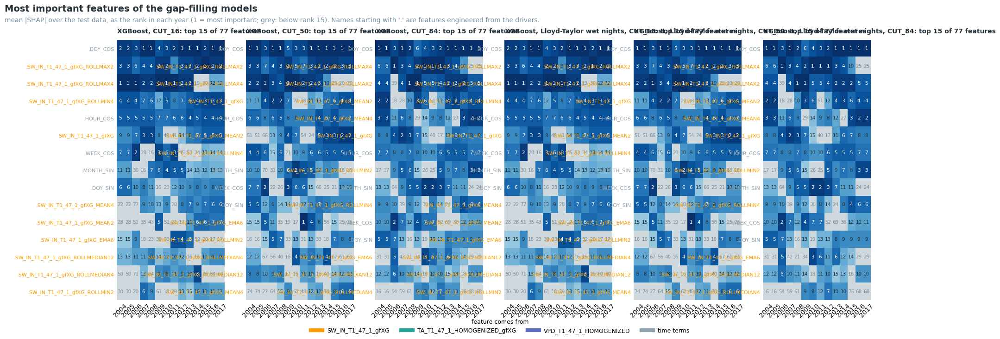

In [54]:
plot_feature_ranks_per_year(data)

## Step 11: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost, CUT_50

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

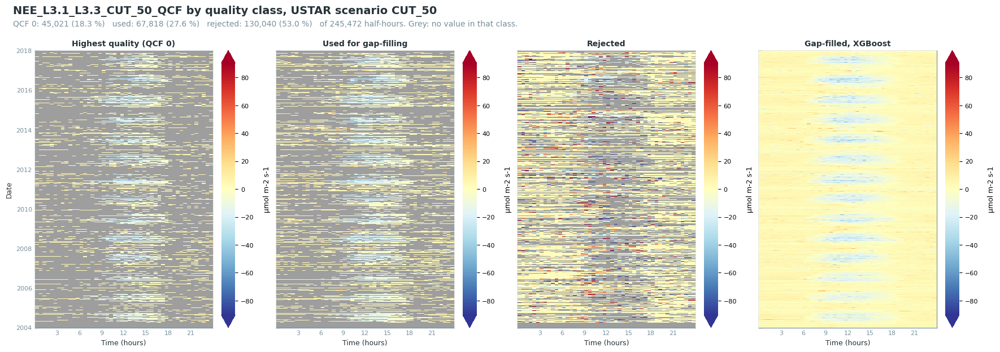

In [55]:
plot_quality_heatmaps(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost, CUT_50

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

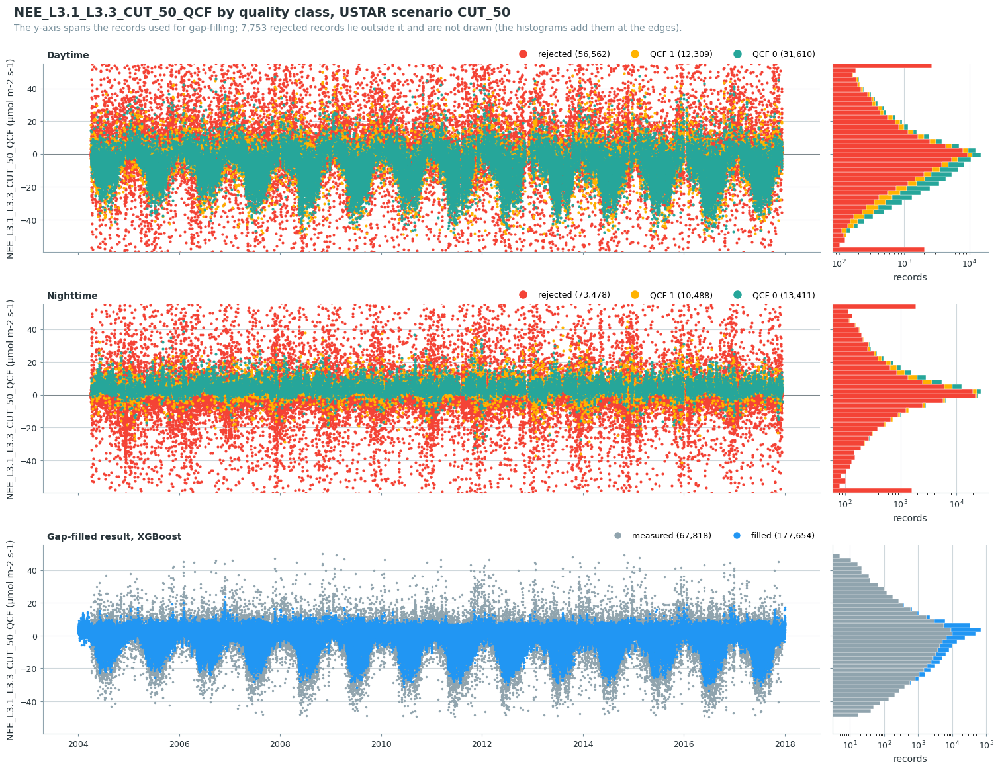

In [56]:
plot_quality_timeseries(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux, CUT_50

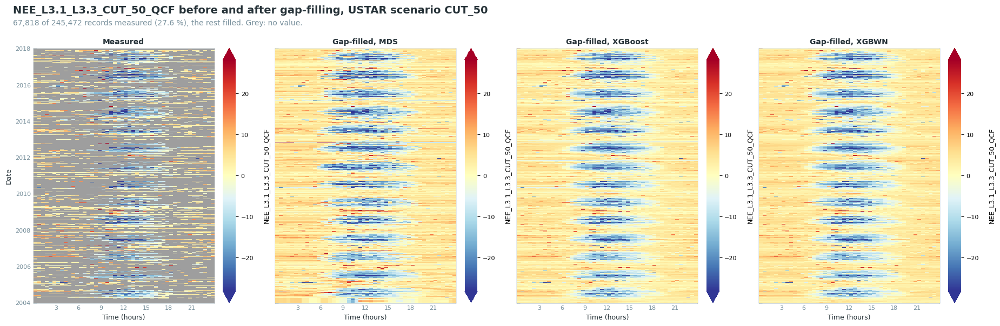

In [57]:
data.plot_gapfilled_heatmaps(ustar_scenario='CUT_50')

### 📊 Plot: cumulative flux, CUT_50

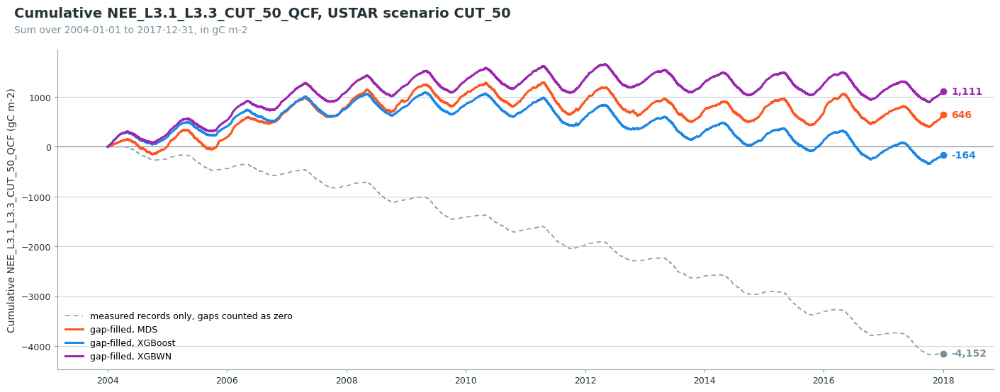

In [58]:
data.plot_cumulative_comparison(
    ustar_scenario='CUT_50',
    conv_factor=UMOL_TO_GC,
    units='gC m-2',
)

### 📊 Plot: cumulative flux of all USTAR scenarios

One line per gap-filling method and USTAR scenario, each method in its own colour. The spread
between CUT_16, CUT_50 and CUT_84 shows how much the annual sum depends on the USTAR threshold. It also contains the variation of the gap-filling model, which
changes with the records each scenario keeps.

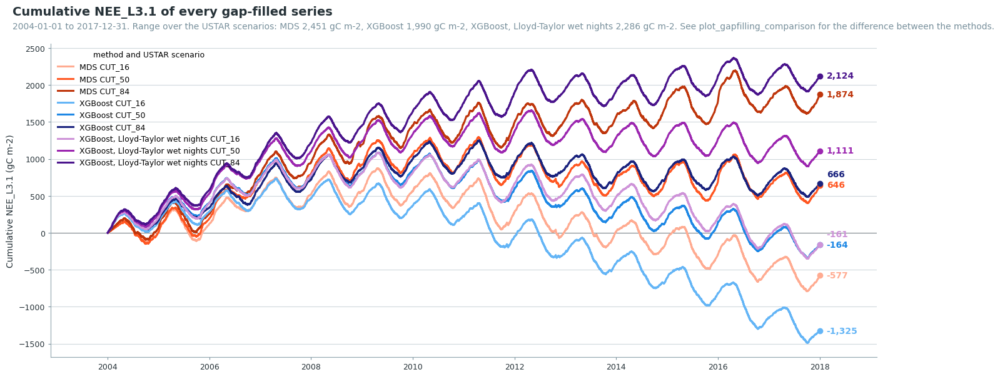

In [59]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year, for each scenario

One line per year; the band is the mean ± 1 SD of the full years. An incomplete last year is left
out of the band.

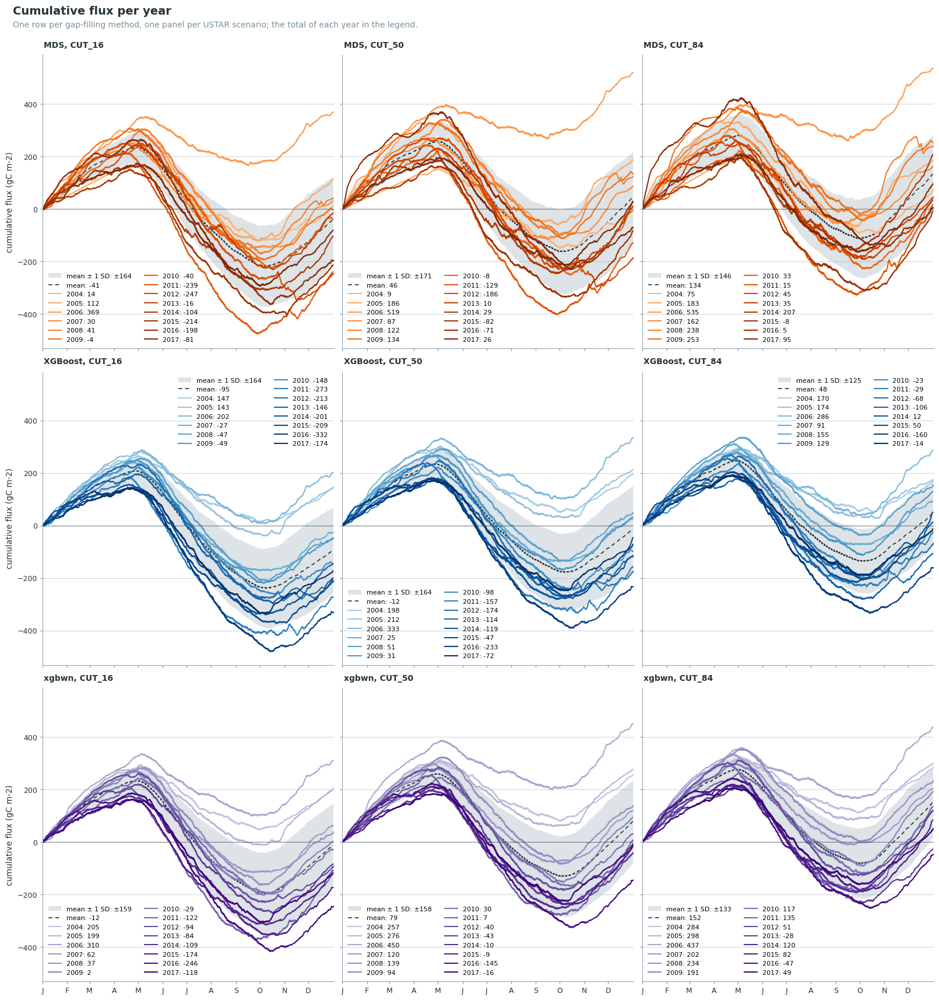

In [60]:
# One row per gap-filling method, one panel per USTAR scenario, on a shared y-axis. Years run
# from light to dark, so the most recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(len(_gf), len(USTAR_SCENARIOS), figsize=(16, 5.5 * len(_gf) + 0.6),
                         sharex=True, sharey=True, layout='constrained', squeeze=False)
for _row, (_method, _cols) in zip(axes, _gf.items()):
    for _ax, _scen in zip(_row, USTAR_SCENARIOS):
        _cum = doy_cumulatives_per_year(data.fpc_df[_cols[_scen]] * UMOL_TO_GC)
        _cum = _cum.loc[:, _cum.notna().any()]
        _years = list(_cum.columns)
        _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
            np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
        if len(_years) > 1:
            _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                       excl_years_from_reference=_partial)
            # Day 366 exists only in leap years, so the band stops before it.
            _ref = _ref.loc[_ref.index < 366]
            # The legend gives the mean and SD of the annual totals of the full years.
            _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
            _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
            _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                             alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
            _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                     linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
        for _shade, _year in zip(_shades, _years):
            _valid = _cum[_year].dropna()
            _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                     label=f"{_year}: {_valid.iloc[-1]:,.0f}")
        _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
        cp.style_axes(_ax)
        cp.panel_label(_ax, f"{_names.get(_method, _method)}, {_scen}")
        _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
        _ax.set_xlim(1, 367)
        _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
    _row[0].set_ylabel('cumulative flux (gC m-2)')
_subtitle = ("One row per gap-filling method, one panel per USTAR scenario; the total of each "
             "year in the legend.")
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative flux per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [61]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=UMOL_TO_GC, units='gC m-2');

Gap-filling methods compared: MDS and XGBoost
           sum       sum                    from         from   gaps   gaps    gaps     gaps
USTAR      MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48      >48
────────────────────────────────────────────────────────────────────────────────────────────
CUT_16    -577    -1,325         -747         18         -765     18    161    -179     -748
CUT_50     646      -164         -810        153         -962      4     46     123     -982
CUT_84   1,874       666       -1,208        119       -1,327      9    -10     183   -1,390
Sums (gC m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_16, same 22,406 held-out records: MDS R² 0.52 RMSE 7.25, XGBoost R² 0.62 RMSE 6.49
CUT_50, same 17,010 held-out records: MDS R² 0.55 RMSE 7.29, XGBoost R² 0.65 RMSE 6.44
CUT_84, same 12,334 held-out records: MDS R² 0.57 RMSE 7.37, XGBoost R² 0.66 RMSE 6.50
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference for every
USTAR scenario.

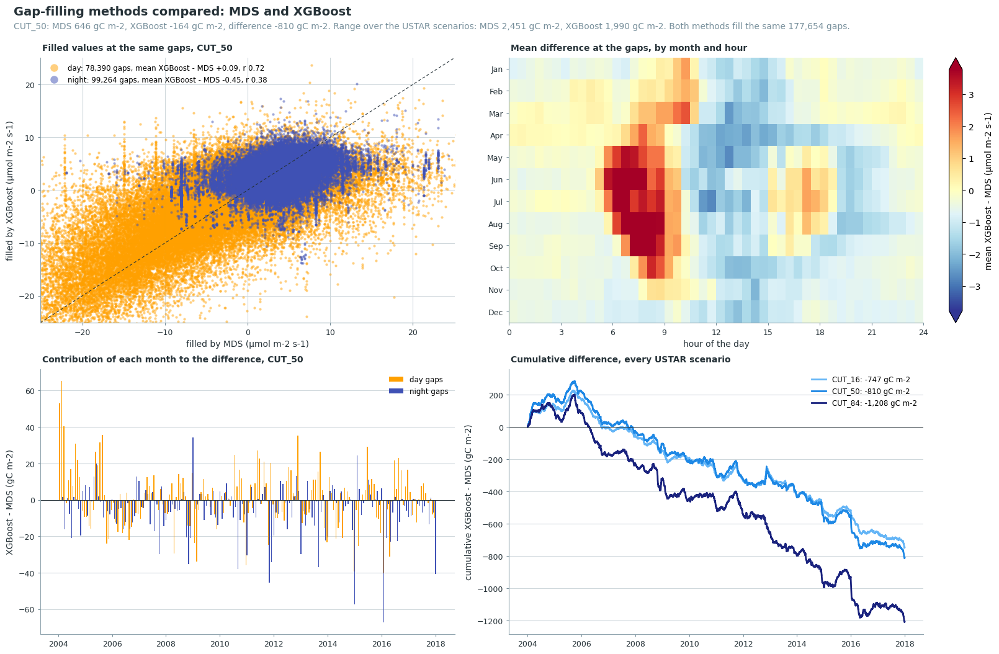

In [62]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario='CUT_50', methods=('mds', 'xgb'),
                               gain=UMOL_TO_GC, units='gC m-2', flux_units=FLUX_UNITS);

## Step 12: uncertainty

Random, USTAR and joint uncertainty of the `UNC_REF` (CUT_50) series of each method, after
Pastorello et al. (2020), at 1 sigma in flux units. In sums the random part adds in quadrature and
the USTAR part as half the difference between the CUT_84 and CUT_16 sums; the difference between
the methods is reported beside them ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#uncertainty)).

### 📋 Table: random uncertainty, records per method

In [63]:
METHOD_NAMES = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
METHOD_COLORS = {_k: _v[1] for _k, _v in cp.METHOD_COLORS.items()}  # the hue of each method
GF_COLS = data.gapfilled_cols()  # {method: {USTAR scenario: gap-filled column}}
_m = data.merged_df(verbose=0)

RANDUNC = {}
for _method, _cols in GF_COLS.items():
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    RANDUNC[_method] = dv.flux.RandomUncertaintyPAS20(
        df=_m,
        fluxcol=data.nongapfilled_cols()[_method][UNC_REF],
        fluxgapfilledcol=_cols[UNC_REF],
        tacol=TA_F,
        vpdcol=VPD_F,  # kPa
        swincol=SW_IN_F,
        vpd_in_kpa=True,
    )
    RANDUNC[_method].run()
    RANDUNC[_method].report_method_summary()


MDS, CUT_50


> Calculating random uncertainty with window size +/-7 days and +/-1 hours (method 1) ...

> Time needed: 2.72s

> Calculating random uncertainty with window size +/-14 days (method 2) ...

> Time needed: 8.43s

> Calculating random uncertainty from similar fluxes (method 3) ...

... (44 outputs left out)

Method  Records Percentage
1: Sliding Window (+/-7d, +/-1h) [ONEFlux]    31682      12.9%
 2: Similar Flux Median (+/-14d) [ONEFlux]   208270      84.8%
3: Similar Flux Median (no window)      5520       2.2%
                 4: Nearest Fluxes         0       0.0%

UNCERTAINTY STATISTICS (umol CO2 m-2 s-1):

Statistic Value (umol CO2 m-2 s-1)
     Mean                   4.1663
  Std Dev                   1.9083
      Min                   0.2550
      Max                  27.3007
    Range                  27.0457

================================================================================

### 📋 Table: random, USTAR and joint uncertainty per record

In [64]:
# Per method, the three columns written to the output file. The USTAR term is stored as a
# magnitude: CUT_84 is not always above CUT_16, and the joint uncertainty uses its square.
UNC = {}
for _method, _cols in GF_COLS.items():
    _gf = _cols[UNC_REF]
    _joint = dv.flux.JointUncertaintyPAS20(
        df=pd.DataFrame({f'{_gf}_RANDUNC': RANDUNC[_method].randunc_series,
                         'lower': _m[_cols[UNC_LOWER]],
                         'upper': _m[_cols[UNC_UPPER]]}),
        randunccol=f'{_gf}_RANDUNC',
        scenario_lower_col='lower',
        scenario_upper_col='upper',
        name=f'{_gf}_JOINTUNC',
    )
    _joint.run()
    print(f"\n{METHOD_NAMES.get(_method, _method)}, {UNC_REF}")
    _joint.report_summary()
    _res = _joint.jointunc_results.rename(columns={_joint.scenarionunccol: f'{_gf}_USTARUNC'})
    _res[f'{_gf}_USTARUNC'] = _res[f'{_gf}_USTARUNC'].abs()
    UNC[_method] = _res[[f'{_gf}_RANDUNC', f'{_gf}_USTARUNC', f'{_gf}_JOINTUNC']]
    assert UNC[_method].notna().all().all(), f"a record of {_gf} has no uncertainty"
UNC_EXPORT = pd.concat(UNC.values(), axis=1)

# The flux and its uncertainty of each method in gC m-2 per half-hour, the input of the sums below.
UNC_FRAMES = {
    _method: pd.DataFrame({
        'flux': _m[_cols[UNC_REF]] * UMOL_TO_GC,
        'var': (UNC[_method][f'{_cols[UNC_REF]}_RANDUNC'] * UMOL_TO_GC) ** 2,
        'lower': _m[_cols[UNC_LOWER]] * UMOL_TO_GC,
        'upper': _m[_cols[UNC_UPPER]] * UMOL_TO_GC,
    })
    for _method, _cols in GF_COLS.items()
}


def period_sums(frame, freq):
    """Sums per period and their 1-sigma uncertainty: the random part in quadrature, the USTAR
    part as half the spread of the CUT_84 and CUT_16 sums."""
    s = frame.resample(freq).sum()
    out = pd.DataFrame({'sum': s['flux'], 'random': np.sqrt(s['var']),
                        'USTAR': ((s['upper'] - s['lower']) / 2).abs()})
    out['joint'] = np.sqrt(out['random'] ** 2 + out['USTAR'] ** 2)
    return out


MDS, CUT_50


================================================================================

JOINT UNCERTAINTY (PAS20) SUMMARY

================================================================================

Output column: NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC  |  records with estimate: 245,472

random term      mean: 4.2870  median: 3.7969

... (17 outputs left out)

random term      mean: 4.1663  median: 3.6600

scenario term    mean: 0.2153  median: 0.2050

joint            mean: 4.3773  median: 3.8184

================================================================================

### 📋 Table: annual sums with their uncertainty

`random`, `USTAR` and `joint` are 1-sigma uncertainties of the annual sum of each method. The
second table gives the difference between the methods, which is reported beside the joint
uncertainty and not included in it. An incomplete last year covers only part of it.

In [65]:
ANNUAL_UNC = {_method: period_sums(_f, 'YS').rename(index=lambda _t: _t.year)
              for _method, _f in UNC_FRAMES.items()}
print(f"Annual sums of the {UNC_REF} series and their uncertainty (gC m-2, 1 sigma)")
display(pd.concat({METHOD_NAMES.get(_k, _k): _v for _k, _v in ANNUAL_UNC.items()},
                  names=['method', 'year']).round(1))

if len(ANNUAL_UNC) > 1:
    _names = [METHOD_NAMES.get(_k, _k) for _k in ANNUAL_UNC]
    _s = pd.DataFrame({_n: _v['sum'] for _n, _v in zip(_names, ANNUAL_UNC.values())})
    _diff = pd.DataFrame({f'{_b} - {_a}': _s[_b] - _s[_a]
                          for _i, _a in enumerate(_names) for _b in _names[_i + 1:]})
    _diff.index.name = 'year'
    print(f"\nDifference between the methods (gC m-2), not part of the joint uncertainty")
    display(_diff.round(1))

Annual sums of the CUT_50 series and their uncertainty (gC m-2, 1 sigma)


sum  random  USTAR  joint
method  year                             
MDS     2004    9.4    12.2   30.9   33.2
        2005  186.3    12.1   35.7   37.7
        2006  518.8    12.2   83.3   84.2
        2007   86.7    12.4   66.2   67.4
        2008  121.7    12.7   98.5   99.3
        2009  133.7    12.0  128.4  129.0
        2010   -8.0    12.6   36.6   38.7
        2011 -129.1    15.0  127.3  128.2
        2012 -185.8    13.7  145.9  146.6
        2013   10.4    15.0   25.3   29.4
        2014   28.6    16.7  155.2  156.1
        2015  -82.4    14.5  102.7  103.7
        2016  -70.8    14.6  101.2  102.2
        2017   26.2    12.5   88.2   89.1
XGBoost 2004  198.5    11.3   11.6   16.2
        2005  211.5    11.4   15.3   19.1
        2006  333.5    12.0   41.9   43.6
        2007   25.0    12.3   58.9   60.2
        2008   50.6    12.5  100.8  101.6
        2009   31.4    11.7   88.9   89.7
        2010  -98.5    12.4   62.4   63.7
        2011 -156.9    15.0  122.0  123.0
        2012 -173.7    13.5   72.1   73.3
        2013 -114.5    14.6   19.6   24.4
        2014 -118.5    16.6  106.3  107.6
        2015  -46.9    14.0  129.5  130.3
        2016 -233.3    14.1   85.8   87.0
        2017  -72.3    12.1   79.9   80.8
xgbwn   2004  257.5    11.2   39.3   40.9
        2005  275.9    11.4   49.5   50.8
        2006  450.3    12.0   63.5   64.7
        2007  119.5    12.3   69.8   70.9
        2008  139.4    12.5   98.2   99.0
        2009   93.6    11.7   94.6   95.3
        2010   30.4    12.3   73.4   74.4
        2011    6.7    14.7  128.7  129.6
        2012  -40.2    13.4   72.3   73.5
        2013  -42.9    14.5   28.3   31.9
        2014   -9.6    16.4  114.1  115.3
        2015   -8.7    14.0  128.1  128.8
        2016 -144.9    14.1   99.5  100.5
        2017  -15.9    12.2   83.4   84.3


Difference between the methods (gC m-2), not part of the joint uncertainty


,XGBoost - MDS,xgbwn - MDS,xgbwn - XGBoost
year,,,
2004,189.1,248.1,59.0
2005,25.2,89.6,64.4
2006,-185.3,-68.5,116.9
2007,-61.7,32.8,94.5
2008,-71.1,17.6,88.8
2009,-102.3,-40.0,62.2
2010,-90.4,38.4,128.8
2011,-27.8,135.7,163.6
2012,12.2,145.6,133.4


### 📊 Plot: annual sums with their uncertainty

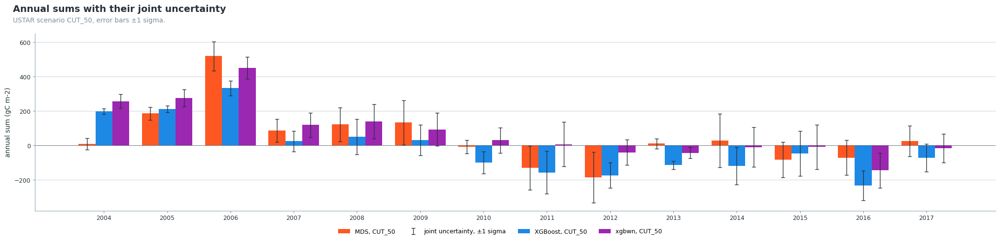

In [66]:
_methods = list(ANNUAL_UNC)
_years = ANNUAL_UNC[_methods[0]].index
_width = 0.8 / len(_methods)
_end = _m.index[-1]
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 5), layout='constrained')
for _i, _method in enumerate(_methods):
    _a = ANNUAL_UNC[_method]
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, _a['sum'], _width, color=METHOD_COLORS.get(_method, cp.KEPT),
           label=f'{METHOD_NAMES.get(_method, _method)}, {UNC_REF}')
    ax.errorbar(_x, _a['sum'], yerr=_a['joint'], fmt='none', ecolor=cp.INK, capsize=3,
                linewidth=1, label='joint uncertainty, ±1 sigma' if _i == 0 else None)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual sum (gC m-2)')
cp.style_axes(ax)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(_methods) + 1, fontsize=9)
cp.figure_title(fig, 'Annual sums with their joint uncertainty',
                f"USTAR scenario {UNC_REF}, error bars ±1 sigma."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: cumulative flux per year with its uncertainty

One panel per year, one line and band per gap-filling method. The band is the joint uncertainty,
accumulated from 1 January: the random part in quadrature, the USTAR part as half the spread of
the cumulative CUT_84 and CUT_16 sums. Where the bands of two methods do not overlap, the methods
differ by more than the joint uncertainty.

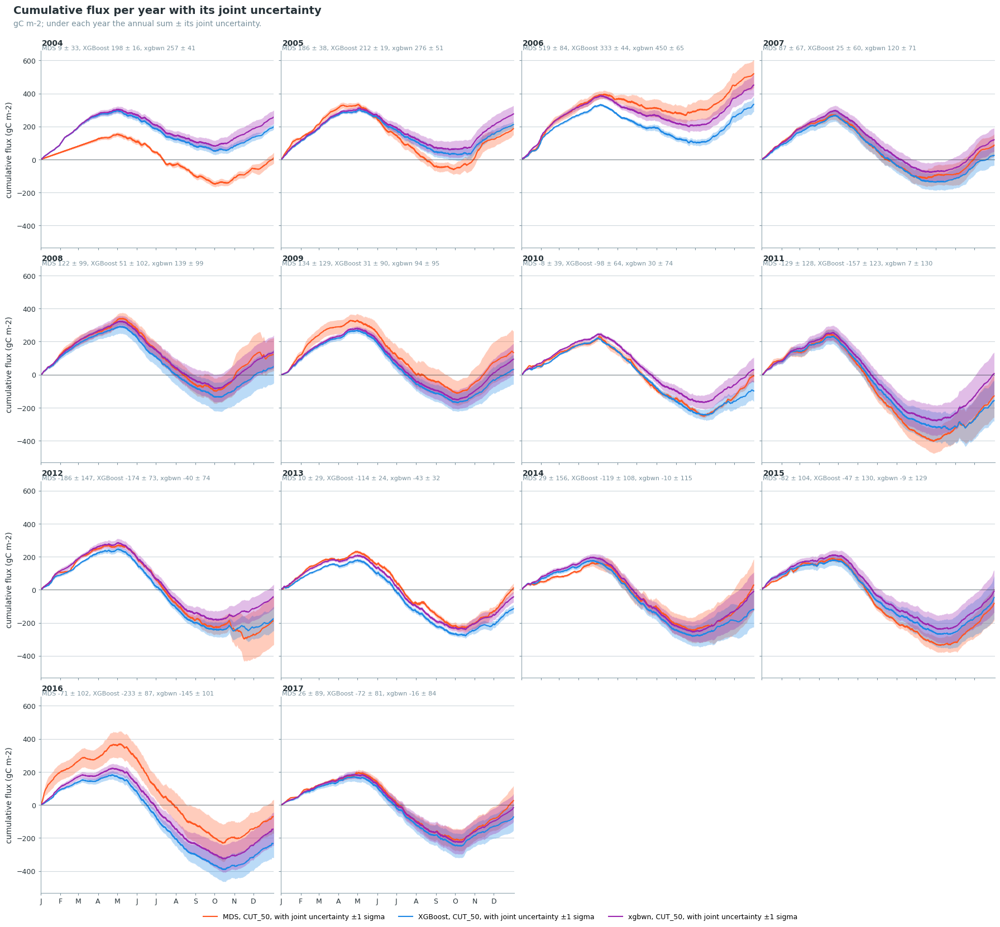

In [67]:
_years = sorted(set(_m.index.year))
_end = _m.index[-1]
_ncol = min(4, len(_years))
_nrow = -(-len(_years) // _ncol)
_month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.2 * _ncol + 1, 3.8 * _nrow + 1.4), sharex=True,
                         sharey=True, layout='constrained', squeeze=False)
for _ax, _year in zip(axes.flat, _years):
    _totals = []
    for _method, _f in UNC_FRAMES.items():
        _d = _f.loc[str(_year)]
        _doy = (_d.index.dayofyear + (_d.index.hour + _d.index.minute / 60) / 24).to_numpy()
        _cum = _d['flux'].cumsum()
        _joint = np.sqrt(_d['var'].cumsum()
                         + ((_d['upper'].cumsum() - _d['lower'].cumsum()) / 2) ** 2)
        _color = METHOD_COLORS.get(_method, cp.KEPT)
        _name = METHOD_NAMES.get(_method, _method)
        _ax.fill_between(_doy, _cum - _joint, _cum + _joint, color=_color, alpha=0.3,
                         linewidth=0)
        _ax.plot(_doy, _cum, color=_color, linewidth=1.5,
                 label=f'{_name}, {UNC_REF}, with joint uncertainty ±1 sigma')
        _totals.append(f"{_name} {_cum.iloc[-1]:,.0f} ± {_joint.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, f"{_year}")
    _ax.text(0.005, 1.0, ", ".join(_totals), transform=_ax.transAxes, ha='left', va='bottom',
             fontsize=8, color=cp.MUTED)
    _ax.set_xticks(_month_starts, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
for _ax in axes.flat[len(_years):]:
    _ax.set_visible(False)
for _row in axes:
    _row[0].set_ylabel('cumulative flux (gC m-2)')
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(UNC_FRAMES), fontsize=9)
cp.figure_title(fig, 'Cumulative flux per year with its joint uncertainty',
                "gC m-2; under each year the annual sum ± its joint uncertainty."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

### 📊 Plot: daily sums with their uncertainty

Two panels per gap-filling method: the daily sum with its joint uncertainty, then the uncertainty
of the daily sums and its two parts.

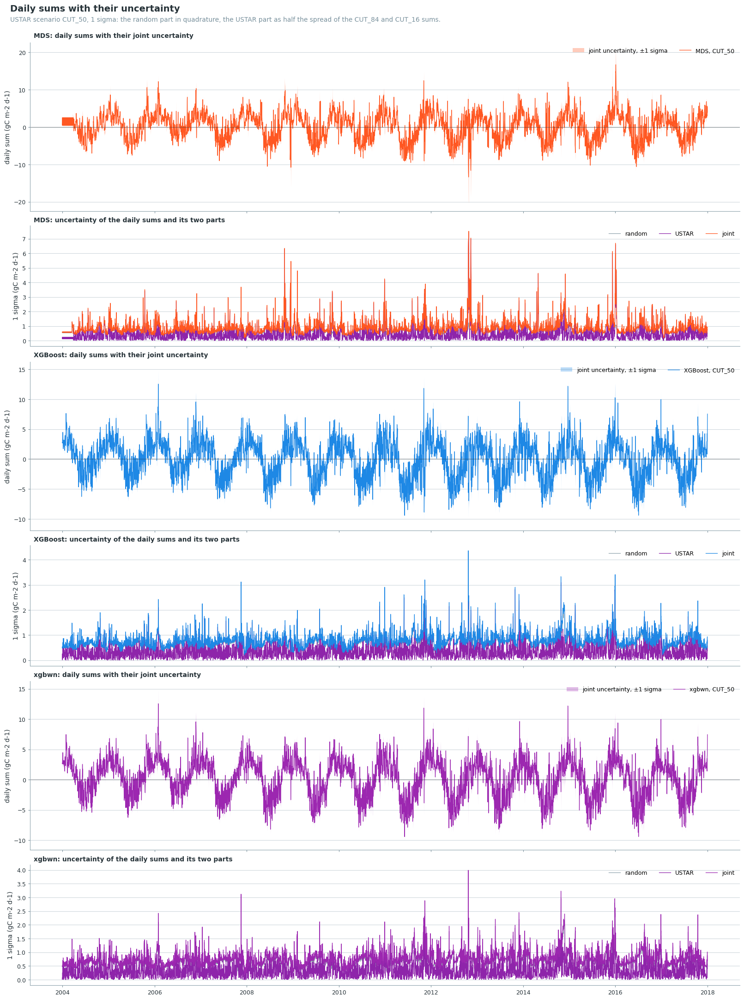

In [68]:
_methods = list(UNC_FRAMES)
fig, axs = plt.subplots(2 * len(_methods), 1, figsize=(16, 7 * len(_methods) + 0.6), sharex=True,
                        layout='constrained', height_ratios=[1.4, 1] * len(_methods))
for _i, _method in enumerate(_methods):
    _day = period_sums(UNC_FRAMES[_method], 'D')
    _color = METHOD_COLORS.get(_method, cp.KEPT)
    _name = METHOD_NAMES.get(_method, _method)
    _top, _bottom = axs[2 * _i], axs[2 * _i + 1]
    _top.fill_between(_day.index, _day['sum'] - _day['joint'], _day['sum'] + _day['joint'],
                      color=_color, alpha=0.3, linewidth=0, label='joint uncertainty, ±1 sigma')
    _top.plot(_day.index, _day['sum'], color=_color, linewidth=0.9, label=f'{_name}, {UNC_REF}')
    _top.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    _top.set_ylabel('daily sum (gC m-2 d-1)')
    cp.panel_label(_top, f'{_name}: daily sums with their joint uncertainty')
    for _col, _c in (('random', cp.KEPT), ('USTAR', cp.TEST_COLORS[2]), ('joint', _color)):
        _bottom.plot(_day.index, _day[_col], color=_c, linewidth=0.9, label=_col)
    _bottom.set_ylabel('1 sigma (gC m-2 d-1)')
    cp.panel_label(_bottom, f'{_name}: uncertainty of the daily sums and its two parts')
for _ax in axs:
    cp.style_axes(_ax)
    _ax.legend(frameon=False, fontsize=9, loc='upper right', ncol=3)
cp.figure_title(fig, 'Daily sums with their uncertainty',
                f"USTAR scenario {UNC_REF}, 1 sigma: the random part in quadrature, the USTAR part "
                f"as half the spread of the {UNC_UPPER} and {UNC_LOWER} sums.")
plt.show()

### 📊 Plot: heatmaps of the flux and its uncertainty

One row per gap-filling method, date against time of day. The random uncertainty grows with the
size of the flux. The USTAR uncertainty is zero where all three scenarios keep the measured
record, and appears only where a record was removed in one scenario and filled.

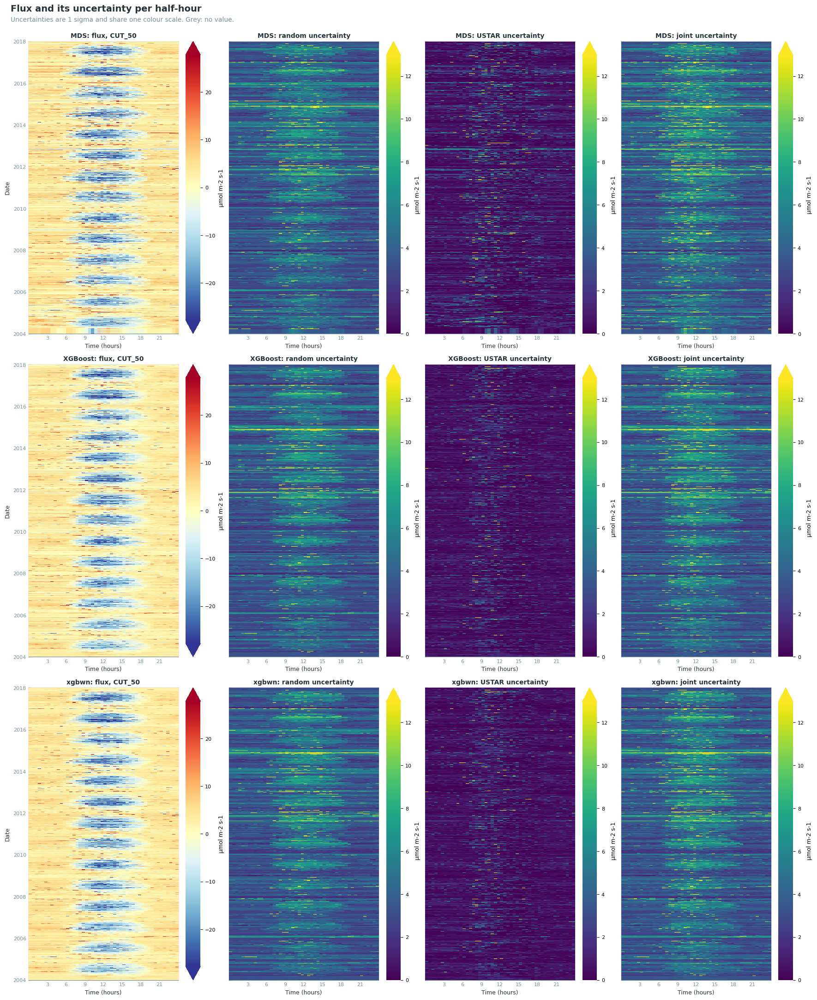

In [69]:
# The flux and its three uncertainties per half-hour. All fluxes share one colour scale, all
# uncertainties another.
_methods = list(UNC_FRAMES)
_flim = max(float(_m[GF_COLS[_k][UNC_REF]].abs().quantile(0.99)) for _k in _methods)
_ulim = max(float(UNC[_k][f'{GF_COLS[_k][UNC_REF]}_JOINTUNC'].quantile(0.99)) for _k in _methods)
fig, axs = plt.subplots(len(_methods), 4, figsize=(17.6, 7 * len(_methods) + 0.6), sharey=True,
                        layout='constrained', squeeze=False)
for _row, _method in zip(axs, _methods):
    _gf = GF_COLS[_method][UNC_REF]
    _name = METHOD_NAMES.get(_method, _method)
    _panels = [
        (f'{_name}: flux, {UNC_REF}', _m[_gf], cp.HEATMAP_CMAP, -_flim, _flim, 'both'),
        (f'{_name}: random uncertainty', UNC[_method][f'{_gf}_RANDUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: USTAR uncertainty', UNC[_method][f'{_gf}_USTARUNC'], 'viridis', 0, _ulim, 'max'),
        (f'{_name}: joint uncertainty', UNC[_method][f'{_gf}_JOINTUNC'], 'viridis', 0, _ulim, 'max'),
    ]
    for _j, (_ax, (_title, _series, _cmap, _vmin, _vmax, _extend)) in enumerate(zip(_row, _panels)):
        dv.plotting.HeatmapDateTime(series=_series, verbose=False).plot(
            ax=_ax, fig=fig, vmin=_vmin, vmax=_vmax, cmap=_cmap, cb_extend=_extend,
            cb_digits_after_comma='auto', cb_labelsize=8, zlabel=FLUX_UNITS,
            color_bad=cp.NAN_COLOR, as_image=True, format_style=cp.heatmap_style(_title))
        # The unit label next to its colour bar, not halfway to the next panel.
        _cb = _ax.images[-1].colorbar if _ax.images else None
        if _cb is not None:
            _cb.set_label(FLUX_UNITS, size=9, labelpad=4)
        if _j:
            plt.setp(_ax.get_yticklabels(), visible=False)
            _ax.yaxis.get_label().set_visible(False)
cp.figure_title(fig, 'Flux and its uncertainty per half-hour',
                'Uncertainties are 1 sigma and share one colour scale. Grey: no value.')
plt.show()

## 💾 Step 13: export

The output file holds only what this notebook adds: every column the chain created and the three
uncertainty columns of Step 12 for each gap-filling method. The input columns stay unchanged in the
input file; the merge into the fullset joins the outputs of the flux notebooks with it on the
timestamp.

In [70]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(UNC_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(UNC_EXPORT.columns) <= set(out_df.columns), "uncertainty columns missing from the output"
print(f"Uncertainty columns in the output: {list(UNC_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 118 (L2: 12, L3.1: 9, L3.2: 13, L3.3: 21, 
L4.1: 18, L4.2: 42, other: 3)

> No variables in the input data were overwritten, only new variables added.

Uncertainty columns in the output: ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS_JOINTUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_JOINTUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXGWN_RANDUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXGWN_USTARUNC', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXGWN_JOINTUNC']
245,472 records x 132 columns (input columns left out: 366)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\T8_05_FPPC_IRGA75_NEE_OPCO_SEED2_2004-2017.parquet (1.263 seconds).

***

# End of notebook.

In [71]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-11-06 21:46:28
Finished: 2026-11-06 22:35:47
Runtime:  00:49:19 (hh:mm:ss)
